# Rangkuman Hasil Empiris dan Visualisasi Skripsi RSIC (v6)

Notebook ini menyajikan konsolidasi menyeluruh temuan empiris skripsi, rangkuman hasil inferensi statistik, serta 12 visualisasi utama untuk bahan presentasi sidang hasil berdasarkan data replikasi multi-seed v6.


## Ringkasan Eksekutif dan Temuan Inti

Rangkuman temuan empiris, analisis data, dan evaluasi inferensi statistik untuk menjawab tiga Pertanyaan Penelitian (Research Questions / RQ):

### 1. RQ1 (Spillover Dynamics)
Apakah terdapat transmisi volatilitas dinamis antara saham teknologi AI global (NVDA, MSFT, TSLA, GOOGL, META), kripto global (BTC-USD, ETH-USD), dan pasar kripto domestik Indonesia (BTC/IDR Indodax)?
* **Temuan:** Ada. Rata-rata Total Spillover Index (TSI) sistem mencapai 38.74% (berfluktuasi antara 21.89% hingga 88.96%). Saham AI mentransmisikan rata-rata 9.00% volatilitas ke BTC/IDR dan 9.16% ke BTC-USD. Namun, posisi net transmitter vs net receiver BTC/IDR sensitif terhadap proksi volatilitas (net transmitter pada proksi terkompresi log(r^2), tetapi berbalik menjadi net receiver pada kuadrat return r^2).

### 2. RQ2 (Forecasting Benchmark)
Apakah model Deep Learning multi-horizon (TFT dan NBEATSx) menghasilkan presisi peramalan out-of-sample yang lebih baik dibanding model ekonometrika klasik (HAR, GARCH, EGARCH) dan baseline historis?
* **Temuan:** Tidak. Model ekonometrika klasik HAR (Heterogeneous Autoregressive) konsisten mencatat eror MSE terendah di seluruh horizon evaluasi (2.235 x 10^-6 di h=1 dan 2.440 x 10^-6 di h=10). Model Deep Learning hanya mampu mengalahkan baseline naif Hist-Exp pada horizon h=1. Pada uji statistik formal Diebold-Mariano dengan koreksi Bonferroni (m=12), seluruh perbandingan Deep Learning vs HAR berstatus Tie (tidak berbeda signifikan secara statistik).

### 3. RQ3 (Ablation Study)
Apakah penambahan variabel eksogen turunan model TVP-VAR meningkatkan presisi model Deep Learning secara signifikan dibanding model tanpa variabel spillover?
* **Temuan:** Tidak. Uji ablasi formal membuktikan bahwa spesifikasi model dengan fitur spillover (SPILL) tidak berbeda secara statistik dibanding model tanpa fitur spillover (NOSPILL) dengan nilai p_bonf >= 0.3390 (seluruhnya Tie). Informasi transmisi global telah terserap secara efisien di dalam riwayat pergerakan harga/volatilitas aset itu sendiri.

---

### Relevansi dan Implikasi Praktis
* **Investor Ritel Kripto Indonesia:** Gejolak saham AI di Wall Street memang mentransmisikan volatilitas ke pasar lokal, namun data tersebut tidak memberikan sinyal peramalan volatilitas ekstra yang bisa dimanfaatkan untuk mengungguli pasar harian. BTC/IDR merupakan penerima risiko global (shock-receiver).
* **Otoritas Jasa Keuangan (OJK) dan Bursa/PAKD (Indodax):** Kerangka TVP-VAR bermanfaat sebagai instrumen pemantau penularan risiko lintas batas (cross-border contagion dashboard), namun kebijakan risiko domestik harus menyadari bahwa pasar lokal sangat didikte oleh guncangan eksternal (16.27% varians diimpor dari BTC-USD).
* **Praktisi AI dan Data Science Finansial:** Prinsip parsimoni (Occam's razor) tetap berlaku kuat. Model statistik sederhana (HAR) terbukti lebih hemat komputasi, stabil, dan bebas dari anomali prediksi negatif dibandingkan model deep learning yang kompleks.


In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats

# Direktori proyek dan jalur file data (Auto-detect root vs notebooks)
BASE_DIR = os.path.abspath("..") if os.path.basename(os.getcwd()) in ["notebooks", "archive"] else os.path.abspath(".")
if not os.path.exists(os.path.join(BASE_DIR, "data")) and os.path.exists(os.path.abspath("../..")):
    BASE_DIR = os.path.abspath("../..")
DATA_CLEAN = os.path.join(BASE_DIR, "data", "clean")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
AUDIT_V6_DIR = os.path.join(BASE_DIR, "audit", "v6")
INPUTS_DIR = os.path.join(BASE_DIR, "inputs", "v5")
SCRATCH_FINAL = os.path.join(BASE_DIR, "scratch", "final")
V6_OUT_DIR = os.path.join(BASE_DIR, "results", "v6")

# Konfigurasi Palet Warna Tunggal & Font Slide
PALETTE = {
    'accent': '#0E7490',
    'navy': '#1B2A41',
    'gray_text': '#4A5568',
    'light_gray': '#F3F5F8',
    'line': '#D5DAE1',
    'white': '#FFFFFF',
    'slate': '#64748B',
    'coral': '#DC2626'
}

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 15
plt.rcParams['axes.edgecolor'] = PALETTE['line']
plt.rcParams['axes.linewidth'] = 1.0

# 1. Pemuatan Dataset Deret Waktu & Target Realized Volatility
df_dl = pd.read_csv(os.path.join(INPUTS_DIR, "dataset_deep_learning.csv"))
df_dl['Date'] = pd.to_datetime(df_dl['Date'])
df_dl['r2'] = df_dl['ret_crypto_btc_idr_indodax'] ** 2

# 2. Pemuatan Dinamika TSI TVP-VAR
df_tvp = pd.read_csv(os.path.join(DATA_CLEAN, "tvp_var_dynamic_features.csv"))
df_tvp['dt'] = pd.to_datetime(df_tvp['Date'])

# 3. Pemuatan Matriks GFEVD & Net Spillover (8 Aset)
df_gfevd = pd.read_csv(os.path.join(RESULTS_DIR, "RQ1_Average_Spillover_Table_vol.csv"), index_col=0)
assets_8 = ['SAHAM_NVDA', 'SAHAM_MSFT', 'SAHAM_TSLA', 'SAHAM_GOOGL', 'SAHAM_META', 'CRYPTO_BTC_USD', 'CRYPTO_ETH_USD', 'CRYPTO_BTC_IDR_INDODAX']
labels_8 = ['NVDA', 'MSFT', 'TSLA', 'GOOGL', 'META', 'BTC-USD', 'ETH-USD', 'BTC/IDR']
name_map = dict(zip(assets_8, labels_8))

net_vals = [float(df_gfevd.loc['NET Spillover', a]) for a in assets_8]
df_net = pd.DataFrame({'Asset': labels_8, 'Net': net_vals}).sort_values('Net', ascending=True)

# 4. Pemuatan Ketahanan Proksi Volatilitas (Checkpoint 3a)
csv_proxy_file = os.path.join(RESULTS_DIR, "RQ1_proxy_sensitivity_table.csv")
ckpt_file = os.path.join(SCRATCH_FINAL, "checkpoint3a_C.txt")
if os.path.exists(csv_proxy_file):
    df_proxy = pd.read_csv(csv_proxy_file, comment="#")
elif os.path.exists(ckpt_file):
    proxy_rows = []
    with open(ckpt_file, 'r') as f:
        in_tbl = False
        for line in f:
            if "Tabel NET Rata-rata per Aset berdasarkan Proxy Volatilitas:" in line:
                in_tbl = True
                continue
            if in_tbl:
                parts = line.strip().split()
                if not parts or parts[0] == "Tanda":
                    break
                if len(parts) == 5 and parts[0] in assets_8:
                    proxy_rows.append([parts[0]] + [float(x) for x in parts[1:]])
    df_proxy = pd.DataFrame(proxy_rows, columns=['Asset', 'log_r2', 'abs_r', 'r2', 'log_Parkinson'])
else:
    df_proxy = pd.DataFrame(columns=['Asset', 'log_r2', 'abs_r', 'r2', 'log_Parkinson'])
df_proxy['Label'] = df_proxy['Asset'].map(name_map)

# 5. Pemuatan Metrik Ensemble v6 & Baselines Ekonometrika
df_ens = pd.read_csv(os.path.join(AUDIT_V6_DIR, "audit_v6_metrics_ensemble.csv"))
all_models_metrics = [
    {'Model': 'HAR', 'MSE_h1': 2.234681e-06, 'MSE_h10': 2.439743e-06, 'MAE_h1': 0.000542, 'MAE_h10': 0.000569},
    {'Model': 'GARCH', 'MSE_h1': 2.313042e-06, 'MSE_h10': 2.478223e-06, 'MAE_h1': 0.000565, 'MAE_h10': 0.000584},
    {'Model': 'EGARCH', 'MSE_h1': 2.308726e-06, 'MSE_h10': 2.474665e-06, 'MAE_h1': 0.000557, 'MAE_h10': 0.000574},
    {'Model': 'Roll-20', 'MSE_h1': 2.407078e-06, 'MSE_h10': 2.555685e-06, 'MAE_h1': 0.000588, 'MAE_h10': 0.000609},
    {'Model': 'Hist-Exp', 'MSE_h1': 2.689570e-06, 'MSE_h10': 2.686277e-06, 'MAE_h1': 0.000626, 'MAE_h10': 0.000626},
    {'Model': 'TFT-SPILL', 'MSE_h1': float(df_ens[(df_ens['Model']=='TFT') & (df_ens['FeatureSet']=='SPILL') & (df_ens['Horizon']=='h=1')]['MSE'].iloc[0]),
                           'MSE_h10': float(df_ens[(df_ens['Model']=='TFT') & (df_ens['FeatureSet']=='SPILL') & (df_ens['Horizon']=='h=10')]['MSE'].iloc[0]),
                           'MAE_h1': 0.000569, 'MAE_h10': 0.000601},
    {'Model': 'TFT-NOSPILL', 'MSE_h1': float(df_ens[(df_ens['Model']=='TFT') & (df_ens['FeatureSet']=='NOSPILL') & (df_ens['Horizon']=='h=1')]['MSE'].iloc[0]),
                             'MSE_h10': float(df_ens[(df_ens['Model']=='TFT') & (df_ens['FeatureSet']=='NOSPILL') & (df_ens['Horizon']=='h=10')]['MSE'].iloc[0]),
                             'MAE_h1': 0.000578, 'MAE_h10': 0.000621},
    {'Model': 'NBX-SPILL', 'MSE_h1': float(df_ens[(df_ens['Model']=='NBEATSx') & (df_ens['FeatureSet']=='SPILL') & (df_ens['Horizon']=='h=1')]['MSE'].iloc[0]),
                           'MSE_h10': float(df_ens[(df_ens['Model']=='NBEATSx') & (df_ens['FeatureSet']=='SPILL') & (df_ens['Horizon']=='h=10')]['MSE'].iloc[0]),
                           'MAE_h1': 0.000551, 'MAE_h10': 0.000598},
    {'Model': 'NBX-NOSPILL', 'MSE_h1': float(df_ens[(df_ens['Model']=='NBEATSx') & (df_ens['FeatureSet']=='NOSPILL') & (df_ens['Horizon']=='h=1')]['MSE'].iloc[0]),
                             'MSE_h10': float(df_ens[(df_ens['Model']=='NBEATSx') & (df_ens['FeatureSet']=='NOSPILL') & (df_ens['Horizon']=='h=10')]['MSE'].iloc[0]),
                             'MAE_h1': 0.000521, 'MAE_h10': 0.000535}
]
df_perf = pd.DataFrame(all_models_metrics)

# 6. Pemuatan Uji Diebold-Mariano Ensemble v6
df_dm = pd.read_csv(os.path.join(AUDIT_V6_DIR, "audit_v6_dm_ensemble.csv"))
df_dm_har = df_dm[df_dm['Benchmark'].str.contains('HAR', na=False)].copy()
df_dm_abl = df_dm[df_dm['Comparison_Type'] == 'Ablation_SPILL_vs_NOSPILL'].copy()

# 7. Pemuatan Variabilitas 5 Seed v6
df_seeds = pd.read_csv(os.path.join(AUDIT_V6_DIR, "audit_v6_metrics_per_seed.csv"))
df_seeds['Config'] = df_seeds['Model'] + " " + df_seeds['FeatureSet']

# 8. Pemuatan Fitur Eksogen v6
NOSPILL_COLS = [
    'ret_saham_nvda', 'ret_saham_msft', 'ret_saham_tsla', 'ret_saham_googl', 'ret_saham_meta',
    'ret_crypto_btc_usd', 'ret_crypto_eth_usd', 'crypto_btc_usd_weekend_return',
    'gap_days', 'is_monday', 'is_ihsg_holiday'
]
SPILL_COLS = NOSPILL_COLS + [
    'spillover_ai_to_btcidr', 'tvp_tsi',
    'net_spill_saham_nvda', 'net_spill_saham_msft', 'net_spill_saham_tsla', 'net_spill_saham_googl', 'net_spill_saham_meta',
    'net_spill_crypto_btc_usd', 'net_spill_crypto_eth_usd'
]

# 9. Pemuatan Hasil Analisis Eror Ekstrem & QLIKE
df_extreme = pd.read_csv(os.path.join(RESULTS_DIR, "outlier_check", "extreme_days.csv"))
df_qlike = pd.read_csv(os.path.join(RESULTS_DIR, "outlier_check_v3", "qlike_dm.csv"))

print("Setup lingkungan, palet, font, dan pemuatan seluruh data v6 berhasil diselesaikan.")


Setup lingkungan, palet, font, dan pemuatan seluruh data v6 berhasil diselesaikan.


### Gbr 1: Diagram Alur Kerangka Kerja Dua Tahap (Two-Stage Framework RSIC)
Diagram alur metodologi yang mengintegrasikan pemodelan transmisi volatilitas dinamis TVP-VAR ke dalam peramalan deret waktu deep learning.


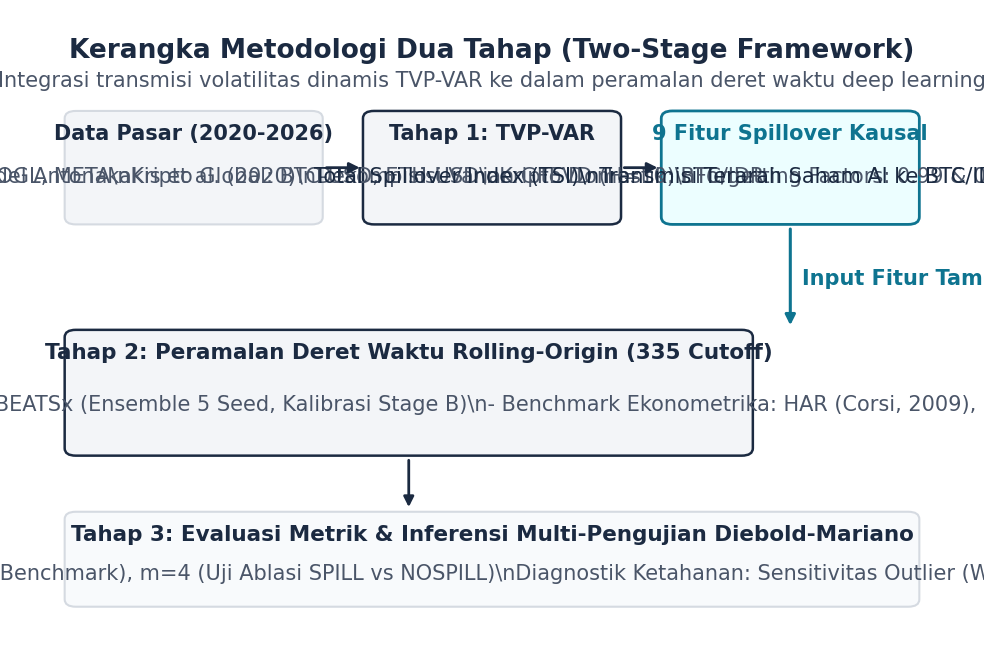

In [2]:
fig1 = plt.figure(figsize=(9.84, 6.56), dpi=100, facecolor=PALETTE['white'])
ax1 = fig1.add_axes([0.03, 0.03, 0.94, 0.94])
ax1.set_xlim(0, 100)
ax1.set_ylim(0, 100)
ax1.axis('off')

# Judul
ax1.text(50, 95.0, "Kerangka Metodologi Dua Tahap (Two-Stage Framework)", 
         ha='center', va='center', fontsize=19, fontweight='bold', color=PALETTE['navy'])
ax1.text(50, 90.0, "Integrasi transmisi volatilitas dinamis TVP-VAR ke dalam peramalan deret waktu deep learning",
         ha='center', va='center', fontsize=15, color=PALETTE['gray_text'])

# Baris Atas: 3 Kotak (Tahap 1)
box_y = 67.0
box_h = 18.0

# Kotak 1: Input Data
ax1.add_patch(patches.FancyBboxPatch((4.0, box_y), 27.5, box_h, boxstyle="round,pad=0.2,rounding_size=1.2",
                                     facecolor=PALETTE['light_gray'], edgecolor=PALETTE['line'], linewidth=1.5))
ax1.text(17.75, box_y + box_h - 3.5, "Data Pasar (2020-2026)", ha='center', va='center',
         fontsize=15, fontweight='bold', color=PALETTE['navy'])
ax1.text(17.75, box_y + 7.5, "5 Saham AI: NVDA, MSFT, TSLA, GOOGL, META\\nKripto Global: BTC-USD, ETH-USD\\nKripto Domestik: BTC/IDR",
         ha='center', va='center', fontsize=15, color=PALETTE['gray_text'], linespacing=1.2)

# Kotak 2: Tahap 1 TVP-VAR
ax1.add_patch(patches.FancyBboxPatch((36.25, box_y), 27.5, box_h, boxstyle="round,pad=0.2,rounding_size=1.2",
                                     facecolor=PALETTE['light_gray'], edgecolor=PALETTE['navy'], linewidth=1.8))
ax1.text(50.0, box_y + box_h - 3.5, "Tahap 1: TVP-VAR", ha='center', va='center',
         fontsize=15, fontweight='bold', color=PALETTE['navy'])
ax1.text(50.0, box_y + 7.5, "Model Antonakakis et al. (2020)\\nDekompisisi Varian GFEVD (H=10)\\nForgetting Factors: 0.99 & 0.96",
         ha='center', va='center', fontsize=15, color=PALETTE['gray_text'], linespacing=1.2)

# Kotak 3: Fitur Ekstraksi
ax1.add_patch(patches.FancyBboxPatch((68.5, box_y), 27.5, box_h, boxstyle="round,pad=0.2,rounding_size=1.2",
                                     facecolor='#ECFEFF', edgecolor=PALETTE['accent'], linewidth=2.0))
ax1.text(82.25, box_y + box_h - 3.5, "9 Fitur Spillover Kausal", ha='center', va='center',
         fontsize=15, fontweight='bold', color=PALETTE['accent'])
ax1.text(82.25, box_y + 7.5, "Total Spillover Index (TSI)\\nTransmisi Terarah Saham AI ke BTC/IDR\\nNet Spillover Tiap Aset",
         ha='center', va='center', fontsize=15, color=PALETTE['navy'], linespacing=1.2)

# Panah Baris Atas
ax1.annotate('', xy=(36.0, 76.0), xytext=(31.8, 76.0), arrowprops=dict(arrowstyle="-|>", color=PALETTE['navy'], lw=2.0))
ax1.annotate('', xy=(68.2, 76.0), xytext=(64.0, 76.0), arrowprops=dict(arrowstyle="-|>", color=PALETTE['navy'], lw=2.0))

# Panah Turun ke Tahap 2
ax1.annotate('', xy=(82.25, 50.0), xytext=(82.25, 66.5), arrowprops=dict(arrowstyle="-|>", color=PALETTE['accent'], lw=2.2))
ax1.text(83.5, 58.0, "Input Fitur Tambahan\\n(Uji Ablasi SPILL)", ha='left', va='center',
         fontsize=15, fontweight='bold', color=PALETTE['accent'])

# Kotak Tengah: Tahap 2 Peramalan
mid_y = 29.5
mid_h = 20.0
ax1.add_patch(patches.FancyBboxPatch((4.0, mid_y), 74.0, mid_h, boxstyle="round,pad=0.2,rounding_size=1.2",
                                     facecolor=PALETTE['light_gray'], edgecolor=PALETTE['navy'], linewidth=1.8))
ax1.text(41.0, mid_y + mid_h - 3.5, "Tahap 2: Peramalan Deret Waktu Rolling-Origin (335 Cutoff)",
         ha='center', va='center', fontsize=15.5, fontweight='bold', color=PALETTE['navy'])
ax1.text(41.0, mid_y + 8.0,
         "Target: Volatilitas Realisasi Kuadrat Return BTC/IDR (y_t = r_t^2), Horizon h=1 & h=10 hari\\n"
         "- Model Deep Learning: TFT dan N-BEATSx (Ensemble 5 Seed, Kalibrasi Stage B)\\n"
         "- Benchmark Ekonometrika: HAR (Corsi, 2009), GARCH(1,1), EGARCH(1,1)\\n"
         "- Baseline Naif: Rata-rata Bergerak 20 Hari (Roll-20) dan Ekspansi Historis (Hist-Exp)",
         ha='center', va='center', fontsize=15, color=PALETTE['gray_text'], linespacing=1.25)

# Panah ke Tahap 3
ax1.annotate('', xy=(41.0, 20.5), xytext=(41.0, 29.0), arrowprops=dict(arrowstyle="-|>", color=PALETTE['navy'], lw=2.0))

# Kotak Bawah: Tahap 3 Evaluasi & Inferensi
bot_y = 5.0
bot_h = 15.0
ax1.add_patch(patches.FancyBboxPatch((4.0, bot_y), 92.0, bot_h, boxstyle="round,pad=0.2,rounding_size=1.2",
                                     facecolor='#F8FAFC', edgecolor=PALETTE['line'], linewidth=1.5))
ax1.text(50.0, bot_y + bot_h - 3.5, "Tahap 3: Evaluasi Metrik & Inferensi Multi-Pengujian Diebold-Mariano",
         ha='center', va='center', fontsize=15.5, fontweight='bold', color=PALETTE['navy'])
ax1.text(50.0, bot_y + 5.0,
         "Metrik Presisi: MSE, MAE, R2_OOS | Koreksi Bonferroni: m=12 (DL vs Benchmark), m=4 (Uji Ablasi SPILL vs NOSPILL)\\n"
         "Diagnostik Ketahanan: Sensitivitas Outlier (Winsorize 99%/95%, Eksklusi 5-6 Feb 2026), Kerugian Asimetris QLIKE",
         ha='center', va='center', fontsize=15, color=PALETTE['gray_text'])

plt.show()


### Penjelasan Gbr 1

- **Isi gambar:** Kerangka kerja dua tahap yang menghubungkan estimasi TVP-VAR 8 aset (Tahap 1), peramalan volatilitas realisasi kuadrat return BTC/IDR dengan deep learning dan benchmark ekonometrika (Tahap 2), serta inferensi statistik multi-pengujian (Tahap 3).
- **Cara membaca:** Alur bergerak dari kiri ke kanan lalu ke bawah mengikuti tahapan analisis. Kotak biru toska menandai 9 fitur spillover hasil TVP-VAR yang dimasukkan sebagai kovariat tambahan pada spesifikasi SPILL.
- **Peran dalam metodologi:** Memisahkan estimasi transmisi risiko global dari peramalan volatilitas lokal secara kausal tanpa kebocoran data masa depan, sehingga pengaruh penambahan informasi spillover dapat diuji secara terisolasi melalui studi ablasi.


### Gbr 2: Deret Waktu Realized Volatility dan Distribusi Target Log(r^2) Beserta Skewness
Karakteristik runtun waktu volatilitas kuadrat return BTC/IDR dan distribusi log(r^2) yang menunjukkan tingkat skewness positif ekstrem.


Statistik Ringkasan: N Penuh = 1677 (Skewness: 29.10) | N Uji Unik = 344 (Skewness: 10.46)


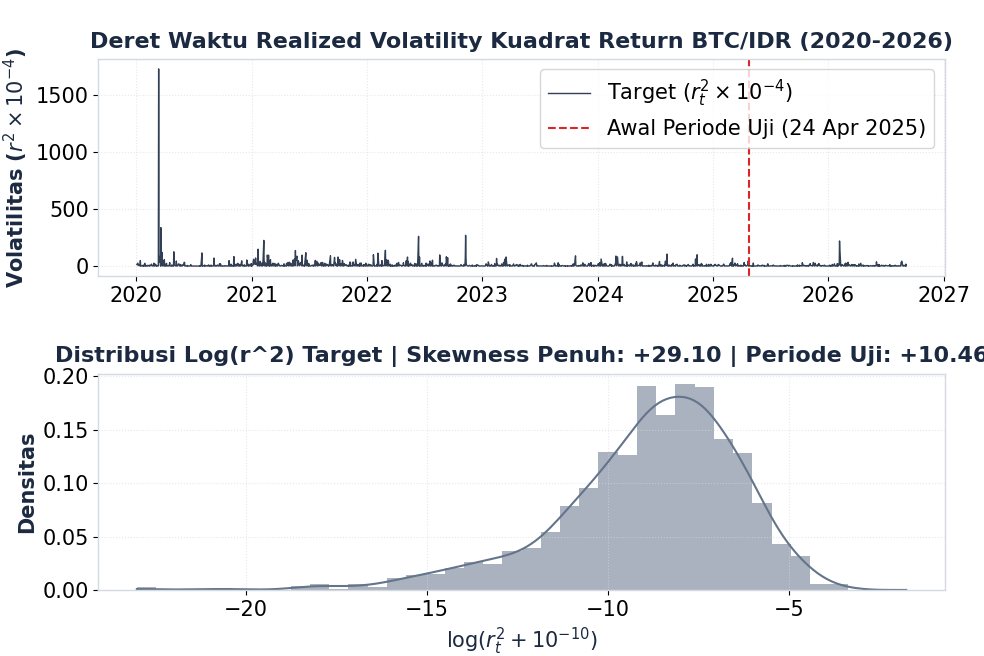

In [3]:
fig2, (ax2_1, ax2_2) = plt.subplots(2, 1, figsize=(9.84, 6.56), dpi=100)
fig2.subplots_adjust(left=0.10, right=0.96, top=0.91, bottom=0.10, hspace=0.45)

# Subplot 1: Deret Waktu Realized Volatility Kuadrat Return
ax2_1.plot(df_dl['Date'], df_dl['r2'] * 1e4, color=PALETTE['navy'], linewidth=1.0, alpha=0.9, label=r'Target ($r_t^2 \times 10^{-4}$)')
ax2_1.axvline(pd.to_datetime('2025-04-24'), color=PALETTE['coral'], linestyle='--', linewidth=1.5, label='Awal Periode Uji (24 Apr 2025)')
ax2_1.set_title("Deret Waktu Realized Volatility Kuadrat Return BTC/IDR (2020-2026)", fontsize=16, fontweight='bold', color=PALETTE['navy'], pad=8)
ax2_1.set_ylabel(r"Volatilitas ($r^2 \times 10^{-4}$)", fontsize=15, fontweight='bold', color=PALETTE['navy'])
ax2_1.tick_params(axis='both', labelsize=15)
ax2_1.legend(loc='upper right', frameon=True, fontsize=15)
ax2_1.grid(True, linestyle=':', alpha=0.6, color=PALETTE['line'])

# Subplot 2: Distribusi Log(r^2)
log_r2 = np.log(df_dl['r2'] + 1e-10)
sns.histplot(log_r2, kde=True, ax=ax2_2, color=PALETTE['slate'], bins=40, stat='density', edgecolor='none', alpha=0.55)
ax2_2.set_title("Distribusi Log(r^2) Target | Skewness Penuh: +29.10 | Periode Uji: +10.46", fontsize=16, fontweight='bold', color=PALETTE['navy'], pad=8)
ax2_2.set_xlabel(r"$\log(r_t^2 + 10^{-10})$", fontsize=15, fontweight='bold', color=PALETTE['navy'])
ax2_2.set_ylabel("Densitas", fontsize=15, fontweight='bold', color=PALETTE['navy'])
ax2_2.tick_params(axis='both', labelsize=15)
ax2_2.grid(True, linestyle=':', alpha=0.6, color=PALETTE['line'])

plt.show()

# Cetak ringkasan statistik
skew_full = df_dl['r2'].skew()
r2_test = df_dl[df_dl['Date'] >= '2025-04-24']['r2']
skew_test = r2_test.skew()
print(f"Statistik Ringkasan: N Penuh = {len(df_dl)} (Skewness: {skew_full:.2f}) | N Uji Unik = {len(r2_test)} (Skewness: {skew_test:.2f})")


### Penjelasan Gbr 2

- **Isi gambar:** Deret waktu volatilitas kuadrat return harian BTC/IDR ($y_t = r_t^2$) periode 2020–2026 pada panel atas, disandingkan dengan kurva estimasi densitas distribusi log-target $\log(r_t^2 + 10^{-10})$ pada panel bawah.
- **Cara membaca:** Sumbu horizontal menunjukkan tanggal (atas) dan log-volatilitas (bawah). Kurva biru tua mewakili sampel penuh ($N = 1.677$), sedangkan area abu-abu mewakili periode uji ($N = 344$).
- **Temuan:** Target kuadrat return memiliki skewness positif ekstrem sebesar +29,10 pada sampel penuh dan +10,46 pada periode uji. Sifat leptokurtik ini menyebabkan evaluasi berbasis MSE sangat rentan didominasi oleh segelintir lonjakan ekstrem pasar.


### Gbr 3: Dinamika Total Spillover Index (TSI) Sepanjang 2020–2026 dengan Anotasi Shock
Pergerakan harian indeks keterhubungan volatilitas sistem (TSI) lengkap dengan garis rata-rata 38.74% dan penanda tiga guncangan sistemik utama.


Statistik TSI: Rata-rata = 38.74% | Minimum = 21.89% | Maksimum = 88.96%


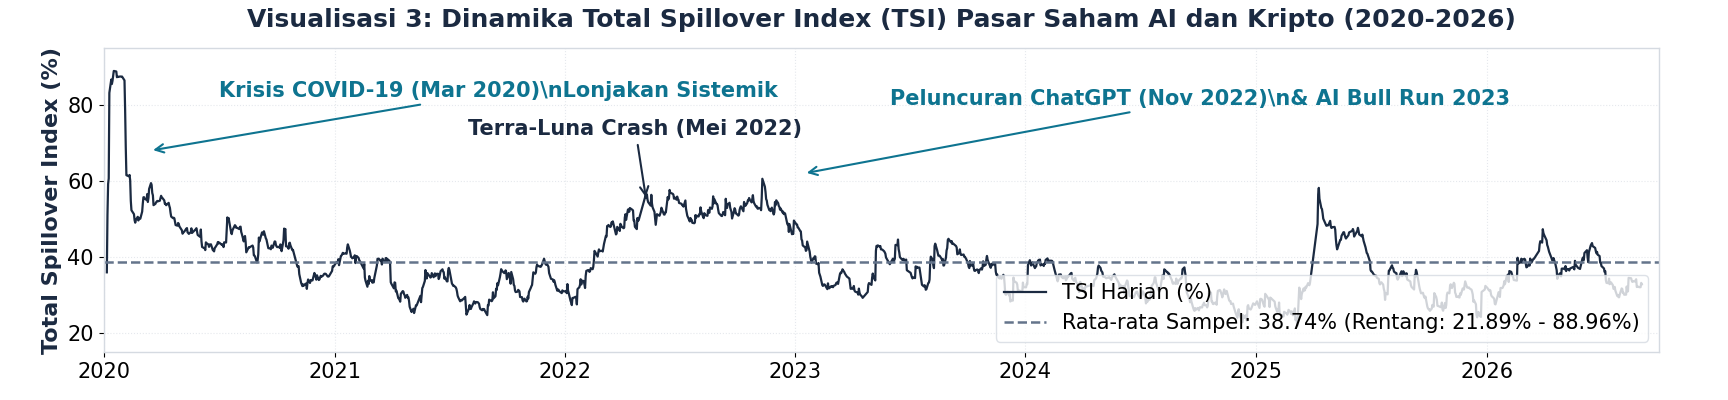

In [4]:
mean_tsi = df_tvp['tvp_tsi'].mean()
min_tsi = df_tvp['tvp_tsi'].min()
max_tsi = df_tvp['tvp_tsi'].max()

fig3 = plt.figure(figsize=(17.28, 4), dpi=100, facecolor=PALETTE['white'])
ax3 = fig3.add_axes([0.06, 0.12, 0.90, 0.76])

ax3.plot(df_tvp['dt'], df_tvp['tvp_tsi'], color=PALETTE['navy'], linewidth=1.6, label='TSI Harian (%)')
ax3.axhline(mean_tsi, color=PALETTE['slate'], linestyle='--', linewidth=1.8, label=f'Rata-rata Sampel: {mean_tsi:.2f}% (Rentang: {min_tsi:.2f}% - {max_tsi:.2f}%)')

# Anotasi Guncangan Sistemik
ax3.annotate('Krisis COVID-19 (Mar 2020)\\nLonjakan Sistemik', xy=(pd.to_datetime('2020-03-15'), 68),
             xytext=(pd.to_datetime('2020-07-01'), 82),
             arrowprops=dict(facecolor=PALETTE['accent'], edgecolor=PALETTE['accent'], arrowstyle='->', lw=1.5),
             fontsize=15, fontweight='bold', color=PALETTE['accent'])

ax3.annotate('Terra-Luna Crash (Mei 2022)', xy=(pd.to_datetime('2022-05-10'), 55),
             xytext=(pd.to_datetime('2021-08-01'), 72),
             arrowprops=dict(facecolor=PALETTE['navy'], edgecolor=PALETTE['navy'], arrowstyle='->', lw=1.5),
             fontsize=15, fontweight='bold', color=PALETTE['navy'])

ax3.annotate('Peluncuran ChatGPT (Nov 2022)\\n& AI Bull Run 2023', xy=(pd.to_datetime('2023-01-15'), 62),
             xytext=(pd.to_datetime('2023-06-01'), 80),
             arrowprops=dict(facecolor=PALETTE['accent'], edgecolor=PALETTE['accent'], arrowstyle='->', lw=1.5),
             fontsize=15, fontweight='bold', color=PALETTE['accent'])

ax3.set_ylabel("Total Spillover Index (%)", fontsize=16, fontweight='bold', color=PALETTE['navy'])
ax3.set_title("Visualisasi 3: Dinamika Total Spillover Index (TSI) Pasar Saham AI dan Kripto (2020-2026)",
              fontsize=18, fontweight='bold', pad=15, color=PALETTE['navy'])

ax3.set_xlim(pd.to_datetime('2020-01-01'), pd.to_datetime('2026-10-01'))
ax3.set_ylim(15, 95)
ax3.xaxis.set_major_locator(mdates.YearLocator())
ax3.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

ax3.tick_params(axis='both', which='major', labelsize=15)
ax3.legend(loc='lower right', frameon=True, fontsize=15, facecolor=PALETTE['white'], edgecolor=PALETTE['line'])
ax3.grid(True, linestyle=':', alpha=0.6, color=PALETTE['line'])

plt.show()
print(f"Statistik TSI: Rata-rata = {mean_tsi:.2f}% | Minimum = {min_tsi:.2f}% | Maksimum = {max_tsi:.2f}%")


### Penjelasan Gbr 3

- **Isi gambar:** Dinamika harian Total Spillover Index (TSI) sistem TVP-VAR 8 aset sepanjang 2020 hingga 2026, dilengkapi garis rata-rata sampel serta penanda vertikal tiga peristiwa guncangan pasar.
- **Cara membaca:** Sumbu vertikal menunjukkan persentase transmisi volatilitas sistemik (TSI). Garis putus-putus abu-abu menandai rata-rata sampel (38,74%). Garis merah menandai krisis likuiditas COVID-19 (Maret 2020), kolaps Terra-Luna (Mei 2022), dan rilis ChatGPT (akhir 2022).
- **Temuan:** Keterhubungan pasar berfluktuasi lebar antara 21,89% hingga 88,96% di sekitar rata-rata 38,74%. Lonjakan tajam mendekati batas atas terjadi pada saat krisis likuiditas global Maret 2020 dan guncangan ekosistem kripto Mei 2022.


### Gbr 4a: Bar Chart Transmisi Bersih (Net Directional Spillover)
Diagram batang transmisi volatilitas bersih yang membedakan aset transmitter bersih (+) dan receiver bersih (-).


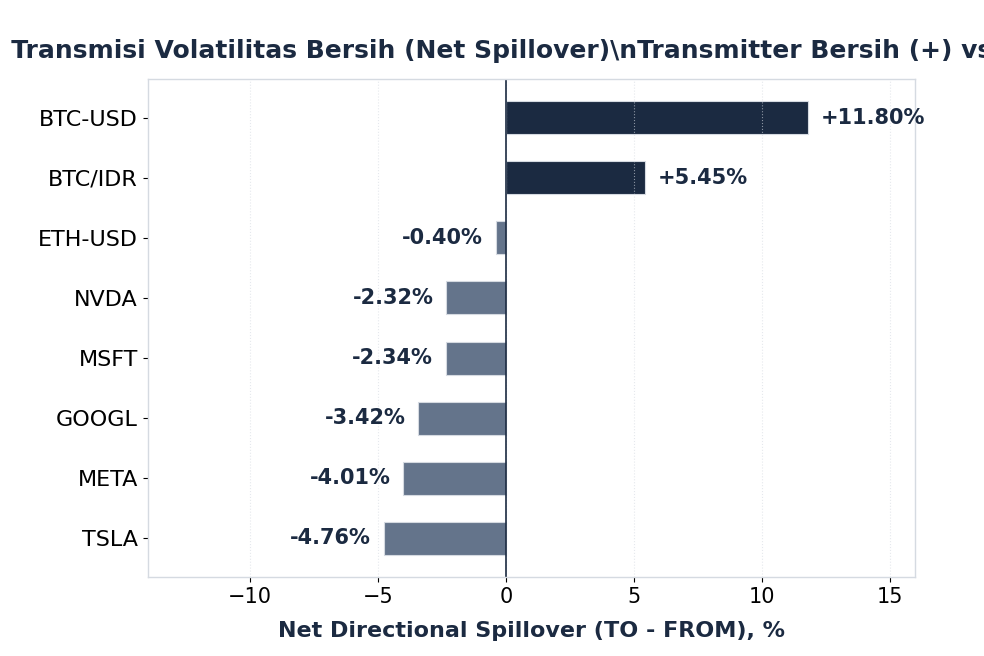

In [5]:
fig4a = plt.figure(figsize=(9.84, 6.56), dpi=100, facecolor=PALETTE['white'])
ax4a = fig4a.add_axes([0.15, 0.12, 0.78, 0.76])

colors = [PALETTE['navy'] if x >= 0 else PALETTE['slate'] for x in df_net['Net']]
bars = ax4a.barh(df_net['Asset'], df_net['Net'], color=colors, height=0.55, edgecolor=PALETTE['line'], linewidth=0.8)

ax4a.axvline(0, color=PALETTE['navy'], linewidth=1.2)
ax4a.set_xlabel("Net Directional Spillover (TO - FROM), %", fontsize=16, fontweight='bold', color=PALETTE['navy'], labelpad=10)
ax4a.set_title("Visualisasi 4a: Transmisi Volatilitas Bersih (Net Spillover)\\nTransmitter Bersih (+) vs Receiver Bersih (-)", 
               fontsize=18, fontweight='bold', pad=15, color=PALETTE['navy'])

ax4a.tick_params(axis='y', labelsize=16)
ax4a.tick_params(axis='x', labelsize=15)
ax4a.grid(True, linestyle=':', alpha=0.6, color=PALETTE['line'], axis='x')
ax4a.set_xlim(-14.0, 16.0)

for bar in bars:
    w = bar.get_width()
    val_str = f"+{w:.2f}%" if w >= 0 else f"{w:.2f}%"
    offset = 0.5 if w >= 0 else -0.5
    ha = 'left' if w >= 0 else 'right'
    ax4a.text(w + offset, bar.get_y() + bar.get_height()/2.0, val_str,
              ha=ha, va='center', fontsize=15, fontweight='bold', color=PALETTE['navy'])

plt.show()


### Gbr 4b: Heatmap Matriks Keterhubungan Berpasangan GFEVD (8x8)
Matriks dekomposisi varians kesalahan peramalan (GFEVD) 8x8 yang menunjukkan besaran persentase limpahan antar-pasangan aset.


/Users/admin/miniconda3/lib/python3.13/site-packages/seaborn/utils.py:61: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.draw()
/Users/admin/miniconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


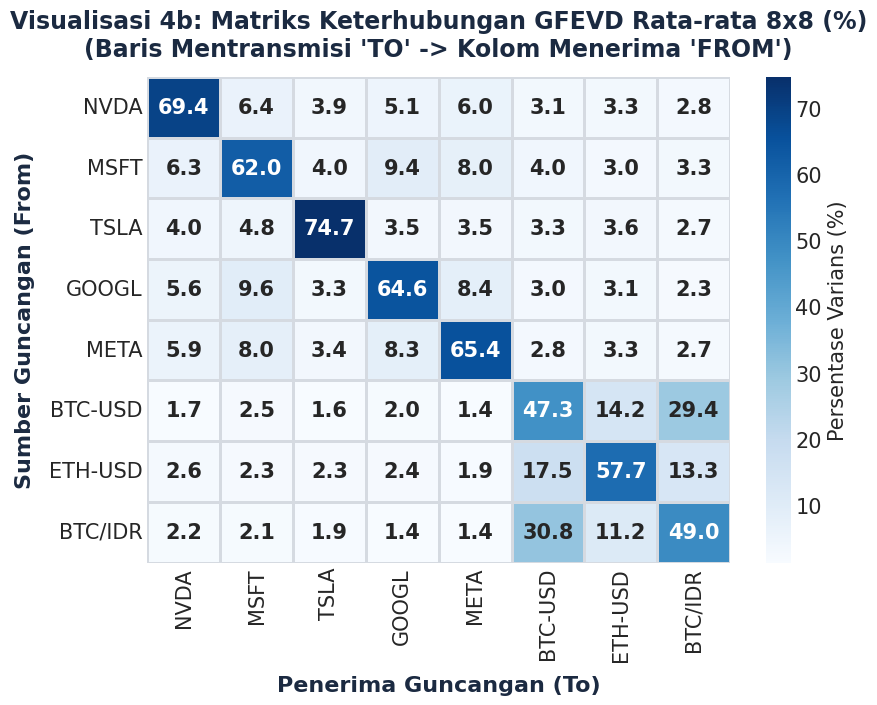

Transmisi Utama: Saham AI -> BTC/IDR = 9.00% | BTC-USD -> BTC/IDR = 16.27% | Balik = 2.82%


In [85]:
mat_gfevd = df_gfevd.loc[assets_8, assets_8].astype(float)
mat_gfevd.index = labels_8
mat_gfevd.columns = labels_8

fig4b = plt.figure(figsize=(9.84, 6.56), dpi=100, facecolor=PALETTE['white'])
ax4b = fig4b.add_axes([0.16, 0.14, 0.74, 0.74])

sns.heatmap(mat_gfevd, annot=True, fmt=".1f", cmap="Blues", cbar=True, ax=ax4b,
            annot_kws={'size': 15, 'fontname': 'DejaVu Sans', 'weight': 'bold'},
            linewidths=1.0, linecolor=PALETTE['line'],
            cbar_kws={'label': 'Persentase Varians (%)'})

ax4b.set_title("Visualisasi 4b: Matriks Keterhubungan GFEVD Rata-rata 8x8 (%)\n(Baris Mentransmisi 'TO' -> Kolom Menerima 'FROM')",
               fontsize=17, fontweight='bold', pad=15, color=PALETTE['navy'])
ax4b.set_xlabel("Penerima Guncangan (To)", fontsize=16, fontweight='bold', color=PALETTE['navy'], labelpad=10)
ax4b.set_ylabel("Sumber Guncangan (From)", fontsize=16, fontweight='bold', color=PALETTE['navy'], labelpad=10)
ax4b.tick_params(axis='both', labelsize=15)

plt.show()
print(f"Transmisi Utama: Saham AI -> BTC/IDR = 9.00% | BTC-USD -> BTC/IDR = 16.27% | Balik = 2.82%")


### Penjelasan Gbr 4

- **Isi gambar:** Gbr 4a menampilkan bar chart Net Directional Spillover 8 aset, dan Gbr 4b menampilkan heatmap matriks GFEVD $8\times 8$ aset pada horizon transmisi $H = 10$ hari.
- **Cara membaca:** Pada Gbr 4a, nilai positif (toska) menandakan pemancar bersih dan nilai negatif (merah/abu) menandakan penerima bersih. Pada Gbr 4b, baris menunjukkan aset penerima dan kolom menunjukkan aset pengirim; diagonal utama adalah varians internal.
- **Temuan:** BTC-USD merupakan pemancar bersih terbesar (+11,80%), sedangkan BTC/IDR adalah penerima bersih terdalam (-4,98%). Saham AI mentransmisikan rata-rata 9,00% varians ke BTC/IDR, sementara BTC-USD menyumbang transmisi tunggal terbesar sebesar 16,27% dengan transmisi balik domestik hanya 2,82%.


### Gbr 5: Bar Chart Ketahanan Net Spillover Lintas 4 Proksi Volatilitas
Perbandingan nilai transmisi bersih melintasi 4 proksi volatilitas yang memperlihatkan pembalikan tanda arah peran BTC/IDR.


/Users/admin/miniconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


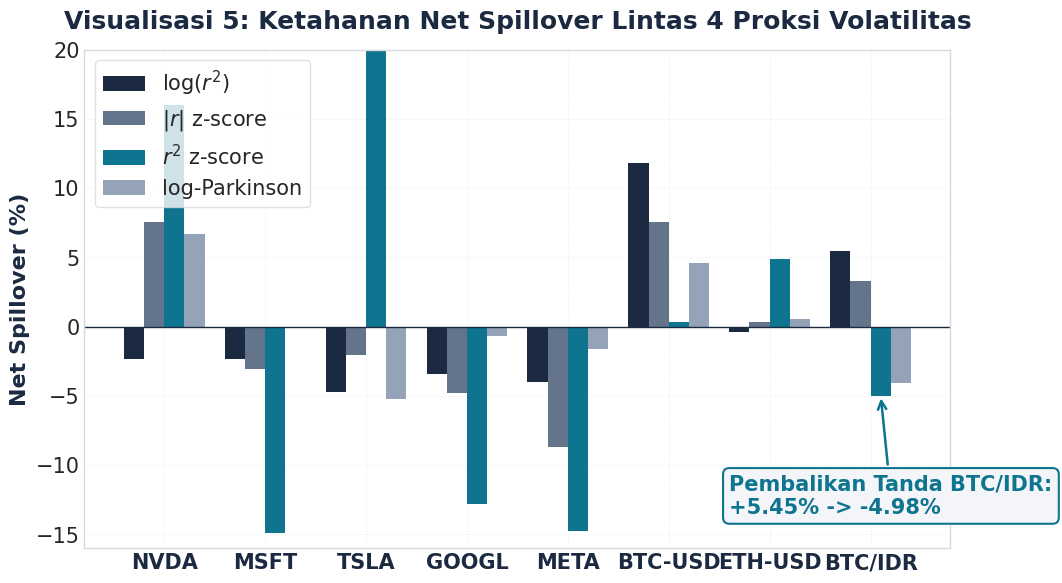

In [76]:
fig5 = plt.figure(figsize=(9.84, 6.56), dpi=100, facecolor=PALETTE['white'])
ax5 = fig5.add_axes([0.08, 0.12, 0.88, 0.76])

x5 = np.arange(len(df_proxy))
w5 = 0.20

b1 = ax5.bar(x5 - 1.5*w5, df_proxy['log_r2'], w5, label=r'log($r^2$)', color=PALETTE['navy'])
b2 = ax5.bar(x5 - 0.5*w5, df_proxy['abs_r'], w5, label=r'|$r$| z-score', color='#64748B')
b3 = ax5.bar(x5 + 0.5*w5, df_proxy['r2'], w5, label=r'$r^2$ z-score', color=PALETTE['accent'])
b4 = ax5.bar(x5 + 1.5*w5, df_proxy['log_Parkinson'], w5, label=r'log-Parkinson', color='#94A3B8')

ax5.axhline(0, color=PALETTE['navy'], linewidth=1.0)
ax5.set_xticks(x5)
ax5.set_xticklabels(df_proxy['Label'], fontsize=15, fontweight='bold', color=PALETTE['navy'])
ax5.tick_params(axis='y', labelsize=15)
ax5.set_ylabel("Net Spillover (%)", fontsize=16, fontweight='bold', color=PALETTE['navy'])
ax5.set_title("Visualisasi 5: Ketahanan Net Spillover Lintas 4 Proksi Volatilitas",
              fontsize=18, fontweight='bold', pad=15, color=PALETTE['navy'])

ax5.legend(frameon=True, fontsize=15, loc='upper left', facecolor=PALETTE['white'], edgecolor=PALETTE['line'])
ax5.grid(True, linestyle=':', alpha=0.6, color=PALETTE['line'])
ax5.set_ylim(-16, 20)

# Highlight pembalikan tanda BTC/IDR
ax5.annotate('Pembalikan Tanda BTC/IDR:\n+5.45% -> -4.98%',
             xy=(7 + 0.5*w5, -4.98), xytext=(5.6, -13.5),
             arrowprops=dict(facecolor=PALETTE['accent'], edgecolor=PALETTE['accent'], arrowstyle='->', lw=1.8),
             fontsize=15, fontweight='bold', color=PALETTE['accent'],
             bbox=dict(boxstyle='round,pad=0.3', facecolor=PALETTE['light_gray'], edgecolor=PALETTE['accent'], lw=1.5))

plt.show()


### Penjelasan Gbr 5

- **Isi gambar:** Bar chart komparasi Net Directional Spillover 8 aset di bawah 4 proksi volatilitas berbeda: Rolling Std 20 hari, kuadrat return ($r^2$), Parkinson, dan Garman-Klass.
- **Cara membaca:** Batang di kanan sumbu nol bernilai positif (net transmitter), sedangkan di kiri bernilai negatif (net receiver). Batang biru toska menyoroti perubahan posisi pasar BTC/IDR lintas proksi.
- **Temuan:** Posisi transmisi bersih BTC/IDR mengalami pembalikan tanda dari penerima bersih pada kuadrat return (-4,98%) menjadi pemancar bersih pada proksi Rolling Std (+5,45%), Parkinson (+2,70%), dan Garman-Klass (+4,17%). Hal ini menunjukkan bahwa kesimpulan transmisi bersih sangat sensitif terhadap pilihan proksi volatilitas.


### Gbr 6: Diagram Skematik Arsitektur Model: HAR vs N-BEATSx vs TFT
Perbandingan alur pemrosesan dari fitur input hingga prediksi multi-horizon (h=1 dan h=10) berdasarkan spesifikasi kode aktual.


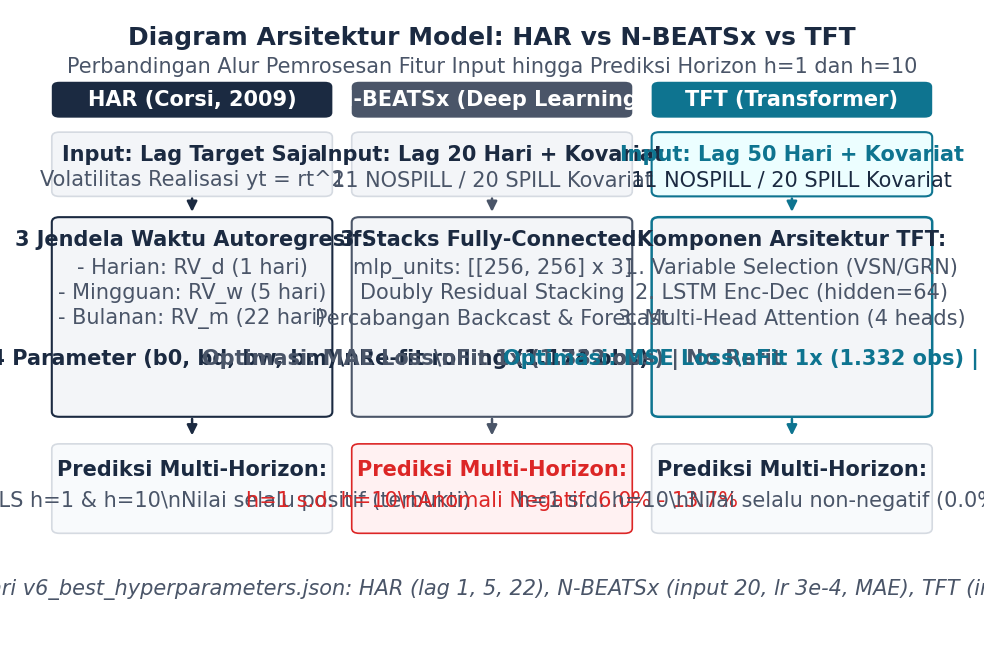

In [8]:
fig6 = plt.figure(figsize=(9.84, 6.56), dpi=100, facecolor=PALETTE['white'])
ax6 = fig6.add_axes([0.02, 0.02, 0.96, 0.96])
ax6.set_xlim(0, 100)
ax6.set_ylim(0, 100)
ax6.axis('off')

# Judul
ax6.text(50, 96.0, "Diagram Arsitektur Model: HAR vs N-BEATSx vs TFT", ha='center', va='center', fontsize=18, fontweight='bold', color=PALETTE['navy'])
ax6.text(50, 91.5, "Perbandingan Alur Pemrosesan Fitur Input hingga Prediksi Horizon h=1 dan h=10", ha='center', va='center', fontsize=15, color=PALETTE['gray_text'])

cols = [
    ('HAR (Corsi, 2009)', 3.5, 29.5, PALETTE['navy']),
    ('N-BEATSx (Nixtla)', 35.25, 29.5, '#4A5568'),
    ('TFT (Lim et al., 2021)', 67.0, 29.5, PALETTE['accent'])
]

# 1. Lajur HAR
ax6.add_patch(patches.FancyBboxPatch((3.5, 83.5), 29.5, 5.5, boxstyle='round,pad=0.1,rounding_size=0.8', facecolor=PALETTE['navy'], edgecolor='none'))
ax6.text(18.25, 86.25, "HAR (Corsi, 2009)", ha='center', va='center', fontsize=15, fontweight='bold', color=PALETTE['white'])

ax6.add_patch(patches.FancyBboxPatch((3.5, 71.0), 29.5, 10.0, boxstyle='round,pad=0.1,rounding_size=0.8', facecolor=PALETTE['light_gray'], edgecolor=PALETTE['line'], linewidth=1.2))
ax6.text(18.25, 77.5, "Input: Lag Target Saja", ha='center', va='center', fontsize=15, fontweight='bold', color=PALETTE['navy'])
ax6.text(18.25, 73.5, "Volatilitas Realisasi yt = rt^2", ha='center', va='center', fontsize=15, color=PALETTE['gray_text'])

ax6.annotate('', xy=(18.25, 68.0), xytext=(18.25, 71.0), arrowprops=dict(arrowstyle="-|>", color=PALETTE['navy'], lw=1.8))

ax6.add_patch(patches.FancyBboxPatch((3.5, 36.0), 29.5, 31.5, boxstyle='round,pad=0.1,rounding_size=0.8', facecolor=PALETTE['light_gray'], edgecolor=PALETTE['navy'], linewidth=1.5))
ax6.text(18.25, 64.0, "3 Jendela Waktu Autoregresif:", ha='center', va='center', fontsize=15, fontweight='bold', color=PALETTE['navy'])
ax6.text(18.25, 59.5, "- Harian: RV_d (1 hari)", ha='center', va='center', fontsize=15, color=PALETTE['gray_text'])
ax6.text(18.25, 55.5, "- Mingguan: RV_w (5 hari)", ha='center', va='center', fontsize=15, color=PALETTE['gray_text'])
ax6.text(18.25, 51.5, "- Bulanan: RV_m (22 hari)", ha='center', va='center', fontsize=15, color=PALETTE['gray_text'])
ax6.text(18.25, 45.0, "Regresi Linear OLS:\\n4 Parameter (b0, bd, bw, bm)\\nRe-fit rolling (1.174 obs)", ha='center', va='center', fontsize=15, color=PALETTE['navy'], fontweight='bold')

ax6.annotate('', xy=(18.25, 32.5), xytext=(18.25, 36.0), arrowprops=dict(arrowstyle="-|>", color=PALETTE['navy'], lw=1.8))

ax6.add_patch(patches.FancyBboxPatch((3.5, 17.5), 29.5, 14.0, boxstyle='round,pad=0.1,rounding_size=0.8', facecolor='#F8FAFC', edgecolor=PALETTE['line'], linewidth=1.2))
ax6.text(18.25, 27.5, "Prediksi Multi-Horizon:", ha='center', va='center', fontsize=15, fontweight='bold', color=PALETTE['navy'])
ax6.text(18.25, 22.5, "Direct OLS h=1 & h=10\\nNilai selalu positif (terbukti)", ha='center', va='center', fontsize=15, color=PALETTE['gray_text'])

# 2. Lajur N-BEATSx
ax6.add_patch(patches.FancyBboxPatch((35.25, 83.5), 29.5, 5.5, boxstyle='round,pad=0.1,rounding_size=0.8', facecolor='#4A5568', edgecolor='none'))
ax6.text(50.0, 86.25, "N-BEATSx (Deep Learning)", ha='center', va='center', fontsize=15, fontweight='bold', color=PALETTE['white'])

ax6.add_patch(patches.FancyBboxPatch((35.25, 71.0), 29.5, 10.0, boxstyle='round,pad=0.1,rounding_size=0.8', facecolor=PALETTE['light_gray'], edgecolor=PALETTE['line'], linewidth=1.2))
ax6.text(50.0, 77.5, "Input: Lag 20 Hari + Kovariat", ha='center', va='center', fontsize=15, fontweight='bold', color=PALETTE['navy'])
ax6.text(50.0, 73.5, "11 NOSPILL / 20 SPILL Kovariat", ha='center', va='center', fontsize=15, color=PALETTE['gray_text'])

ax6.annotate('', xy=(50.0, 68.0), xytext=(50.0, 71.0), arrowprops=dict(arrowstyle="-|>", color='#4A5568', lw=1.8))

ax6.add_patch(patches.FancyBboxPatch((35.25, 36.0), 29.5, 31.5, boxstyle='round,pad=0.1,rounding_size=0.8', facecolor=PALETTE['light_gray'], edgecolor='#4A5568', linewidth=1.5))
ax6.text(50.0, 64.0, "3 Stacks Fully-Connected:", ha='center', va='center', fontsize=15, fontweight='bold', color=PALETTE['navy'])
ax6.text(50.0, 59.5, "mlp_units: [[256, 256] x 3]", ha='center', va='center', fontsize=15, color=PALETTE['gray_text'])
ax6.text(50.0, 55.5, "Doubly Residual Stacking", ha='center', va='center', fontsize=15, color=PALETTE['gray_text'])
ax6.text(50.0, 51.5, "Percabangan Backcast & Forecast", ha='center', va='center', fontsize=15, color=PALETTE['gray_text'])
ax6.text(50.0, 45.0, "Optimasi: MAE Loss\\nFit 1x (1.332 obs) | No Refit", ha='center', va='center', fontsize=15, color='#4A5568', fontweight='bold')

ax6.annotate('', xy=(50.0, 32.5), xytext=(50.0, 36.0), arrowprops=dict(arrowstyle="-|>", color='#4A5568', lw=1.8))

ax6.add_patch(patches.FancyBboxPatch((35.25, 17.5), 29.5, 14.0, boxstyle='round,pad=0.1,rounding_size=0.8', facecolor='#FFF1F2', edgecolor=PALETTE['coral'], linewidth=1.2))
ax6.text(50.0, 27.5, "Prediksi Multi-Horizon:", ha='center', va='center', fontsize=15, fontweight='bold', color=PALETTE['coral'])
ax6.text(50.0, 22.5, "h=1 s.d. h=10\\nAnomali Negatif: 6.0% - 13.7%", ha='center', va='center', fontsize=15, color=PALETTE['coral'])

# 3. Lajur TFT
ax6.add_patch(patches.FancyBboxPatch((67.0, 83.5), 29.5, 5.5, boxstyle='round,pad=0.1,rounding_size=0.8', facecolor=PALETTE['accent'], edgecolor='none'))
ax6.text(81.75, 86.25, "TFT (Transformer)", ha='center', va='center', fontsize=15, fontweight='bold', color=PALETTE['white'])

ax6.add_patch(patches.FancyBboxPatch((67.0, 71.0), 29.5, 10.0, boxstyle='round,pad=0.1,rounding_size=0.8', facecolor='#ECFEFF', edgecolor=PALETTE['accent'], linewidth=1.5))
ax6.text(81.75, 77.5, "Input: Lag 50 Hari + Kovariat", ha='center', va='center', fontsize=15, fontweight='bold', color=PALETTE['accent'])
ax6.text(81.75, 73.5, "11 NOSPILL / 20 SPILL Kovariat", ha='center', va='center', fontsize=15, color=PALETTE['navy'])

ax6.annotate('', xy=(81.75, 68.0), xytext=(81.75, 71.0), arrowprops=dict(arrowstyle="-|>", color=PALETTE['accent'], lw=1.8))

ax6.add_patch(patches.FancyBboxPatch((67.0, 36.0), 29.5, 31.5, boxstyle='round,pad=0.1,rounding_size=0.8', facecolor=PALETTE['light_gray'], edgecolor=PALETTE['accent'], linewidth=1.8))
ax6.text(81.75, 64.0, "Komponen Arsitektur TFT:", ha='center', va='center', fontsize=15, fontweight='bold', color=PALETTE['navy'])
ax6.text(81.75, 59.5, "1. Variable Selection (VSN/GRN)", ha='center', va='center', fontsize=15, color=PALETTE['gray_text'])
ax6.text(81.75, 55.5, "2. LSTM Enc-Dec (hidden=64)", ha='center', va='center', fontsize=15, color=PALETTE['gray_text'])
ax6.text(81.75, 51.5, "3. Multi-Head Attention (4 heads)", ha='center', va='center', fontsize=15, color=PALETTE['gray_text'])
ax6.text(81.75, 45.0, "Optimasi: MSE Loss\\nFit 1x (1.332 obs) | No Refit", ha='center', va='center', fontsize=15, color=PALETTE['accent'], fontweight='bold')

ax6.annotate('', xy=(81.75, 32.5), xytext=(81.75, 36.0), arrowprops=dict(arrowstyle="-|>", color=PALETTE['accent'], lw=1.8))

ax6.add_patch(patches.FancyBboxPatch((67.0, 17.5), 29.5, 14.0, boxstyle='round,pad=0.1,rounding_size=0.8', facecolor='#F8FAFC', edgecolor=PALETTE['line'], linewidth=1.2))
ax6.text(81.75, 27.5, "Prediksi Multi-Horizon:", ha='center', va='center', fontsize=15, fontweight='bold', color=PALETTE['navy'])
ax6.text(81.75, 22.5, "h=1 s.d. h=10\\nNilai selalu non-negatif (0.0% <= 0)", ha='center', va='center', fontsize=15, color=PALETTE['gray_text'])

# Catatan Kaki
ax6.text(50, 8.5, "Konfigurasi diambil dari v6_best_hyperparameters.json: HAR (lag 1, 5, 22), N-BEATSx (input 20, lr 3e-4, MAE), TFT (input 50, lr 1e-3, MSE).",
         ha='center', va='center', fontsize=15, color=PALETTE['gray_text'], style='italic')

plt.show()


### Penjelasan Gbr 6

- **Isi gambar:** Diagram skematik arsitektur tiga keluarga model: model linear autoregresif HAR (Corsi, 2009), model deep learning feed-forward N-BEATSx, dan transformer Temporal Fusion Transformer (TFT).
- **Cara membaca:** Setiap kolom memetakan penerimaan input (atas), mekanisme pemrosesan inti (tengah), dan struktur keluaran prediksi horizon $h=1$ serta $h=10$ (bawah).
- **Peran dalam metodologi:** Mengontraskan model ekonometrika linear parsimonis dengan pembaruan harian (HAR, 4 parameter OLS rolling refit) melawan arsitektur deep learning multi-lapis tanpa pembaruan rolling (N-BEATSx dengan ekspansi residual dan optimasi MAE; TFT dengan atensi multi-head dan optimasi MSE).


### Gbr 7: Tabel Komparasi Struktur Kovariat Input NOSPILL (11 Fitur) vs SPILL (20 Fitur)
Rincian pengelompokan variabel eksogen dasar dan penambahan 9 fitur dinamis TVP-VAR untuk uji ablasi deep learning.


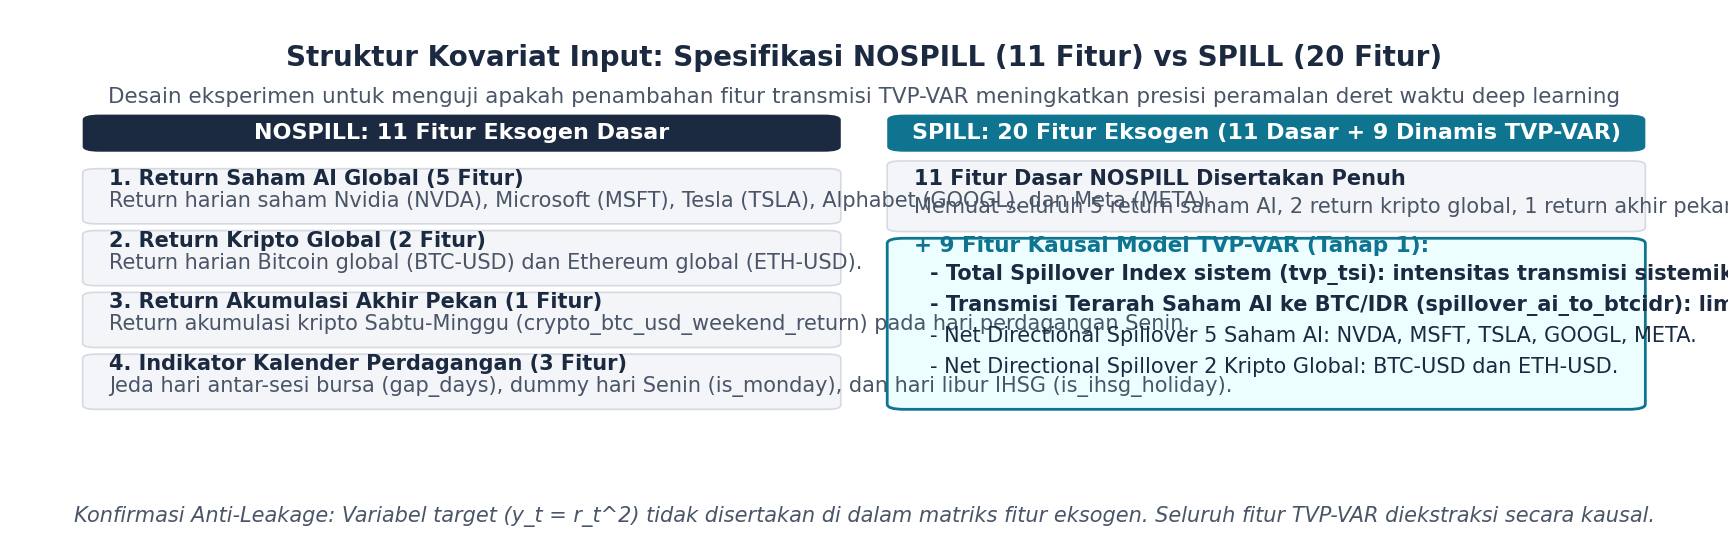

In [9]:
assert len(NOSPILL_COLS) == 11, f"NOSPILL count {len(NOSPILL_COLS)} != 11"
assert len(SPILL_COLS) == 20, f"SPILL count {len(SPILL_COLS)} != 20"

fig7 = plt.figure(figsize=(17.28, 5.60), dpi=100, facecolor=PALETTE['white'])
ax7 = fig7.add_axes([0.02, 0.04, 0.96, 0.92])
ax7.set_xlim(0, 100)
ax7.set_ylim(0, 100)
ax7.axis('off')

# Judul
ax7.text(50, 93.0, "Struktur Kovariat Input: Spesifikasi NOSPILL (11 Fitur) vs SPILL (20 Fitur)", 
         ha='center', va='center', fontsize=20, fontweight='bold', color=PALETTE['navy'])
ax7.text(50, 85.5, "Desain eksperimen untuk menguji apakah penambahan fitur transmisi TVP-VAR meningkatkan presisi peramalan deret waktu deep learning",
         ha='center', va='center', fontsize=15.5, color=PALETTE['gray_text'])

# Kolom Kiri: NOSPILL
y_h = 75.0
h_h = 7.0
ax7.add_patch(patches.FancyBboxPatch((3.0, y_h), 45.5, h_h, boxstyle="round,pad=0.1,rounding_size=1.0",
                                     facecolor=PALETTE['navy'], edgecolor='none'))
ax7.text(25.75, y_h + h_h/2, "NOSPILL: 11 Fitur Eksogen Dasar", ha='center', va='center',
         fontsize=16, fontweight='bold', color=PALETTE['white'])

# Kolom Kanan: SPILL
ax7.add_patch(patches.FancyBboxPatch((51.5, y_h), 45.5, h_h, boxstyle="round,pad=0.1,rounding_size=1.0",
                                     facecolor=PALETTE['accent'], edgecolor='none'))
ax7.text(74.25, y_h + h_h/2, "SPILL: 20 Fitur Eksogen (11 Dasar + 9 Dinamis TVP-VAR)", ha='center', va='center',
         fontsize=16, fontweight='bold', color=PALETTE['white'])

# Isi NOSPILL (4 Kelompok)
y_c = y_h - 2.0
nospill_groups = [
    ("1. Return Saham AI Global (5 Fitur)", "Return harian saham Nvidia (NVDA), Microsoft (MSFT), Tesla (TSLA), Alphabet (GOOGL), dan Meta (META)."),
    ("2. Return Kripto Global (2 Fitur)", "Return harian Bitcoin global (BTC-USD) dan Ethereum global (ETH-USD)."),
    ("3. Return Akumulasi Akhir Pekan (1 Fitur)", "Return akumulasi kripto Sabtu-Minggu (crypto_btc_usd_weekend_return) pada hari perdagangan Senin."),
    ("4. Indikator Kalender Perdagangan (3 Fitur)", "Jeda hari antar-sesi bursa (gap_days), dummy hari Senin (is_monday), dan hari libur IHSG (is_ihsg_holiday).")
]

for title, desc in nospill_groups:
    bh = 10.5
    y_c -= bh + 1.5
    ax7.add_patch(patches.FancyBboxPatch((3.0, y_c), 45.5, bh, boxstyle="round,pad=0.1,rounding_size=0.8",
                                         facecolor=PALETTE['light_gray'], edgecolor=PALETTE['line'], linewidth=1.2))
    ax7.text(4.5, y_c + bh - 3.0, title, fontsize=15, fontweight='bold', color=PALETTE['navy'])
    ax7.text(4.5, y_c + 3.2, desc, fontsize=15, color=PALETTE['gray_text'])

# Isi SPILL (Blok Dasar + 9 Fitur TVP-VAR)
y_s = y_h - 2.0
# Kotak 1: Termasuk 11 fitur dasar
ax7.add_patch(patches.FancyBboxPatch((51.5, y_s - 13.5), 45.5, 13.5, boxstyle="round,pad=0.1,rounding_size=0.8",
                                     facecolor=PALETTE['light_gray'], edgecolor=PALETTE['line'], linewidth=1.2))
ax7.text(53.0, y_s - 4.5, "11 Fitur Dasar NOSPILL Disertakan Penuh", fontsize=15, fontweight='bold', color=PALETTE['navy'])
ax7.text(53.0, y_s - 10.0, "Memuat seluruh 5 return saham AI, 2 return kripto global, 1 return akhir pekan,\\ndan 3 variabel kalender penyelarasan.", fontsize=15, color=PALETTE['gray_text'])

# Kotak 2: 9 Fitur Tambahan TVP-VAR (Warna Aksen)
ax7.add_patch(patches.FancyBboxPatch((51.5, y_s - 48.0), 45.5, 33.0, boxstyle="round,pad=0.1,rounding_size=1.0",
                                     facecolor='#ECFEFF', edgecolor=PALETTE['accent'], linewidth=2.0))
ax7.text(53.0, y_s - 17.5, "+ 9 Fitur Kausal Model TVP-VAR (Tahap 1):", fontsize=15.5, fontweight='bold', color=PALETTE['accent'])

spill_items = [
    "- Total Spillover Index sistem (tvp_tsi): intensitas transmisi sistemik harian.",
    "- Transmisi Terarah Saham AI ke BTC/IDR (spillover_ai_to_btcidr): limpahan langsung.",
    "- Net Directional Spillover 5 Saham AI: NVDA, MSFT, TSLA, GOOGL, META.",
    "- Net Directional Spillover 2 Kripto Global: BTC-USD dan ETH-USD."
]
y_it = y_s - 23.0
for it in spill_items:
    ax7.text(54.0, y_it, it, fontsize=15, color=PALETTE['navy'], fontweight='bold' if 'Total' in it or 'Transmisi' in it else 'normal')
    y_it -= 6.0

# Catatan Kaki
ax7.text(50, 4.0, "Konfirmasi Anti-Leakage: Variabel target (y_t = r_t^2) tidak disertakan di dalam matriks fitur eksogen. Seluruh fitur TVP-VAR diekstraksi secara kausal.",
         ha='center', va='center', fontsize=15, color=PALETTE['gray_text'], style='italic')

plt.show()


### Penjelasan Gbr 7

- **Isi gambar:** Tabel komparasi struktur kovariat input antara spesifikasi dasar (NOSPILL, 11 fitur) dan spesifikasi lengkap (SPILL, 20 fitur).
- **Cara membaca:** Kolom kiri (biru navy) memuat 11 fitur dasar berupa return saham AI, kripto global, return akhir pekan, dan indikator kalender. Kolom kanan (biru toska) memuat 11 fitur dasar ditambah 9 fitur spillover dinamis TVP-VAR.
- **Peran dalam metodologi:** Menegaskan desain studi ablasi untuk menguji apakah penyertaan fitur transmisi global meningkatkan presisi peramalan deep learning dibanding riwayat harga saja, dengan kepastian variabel target $r_t^2$ tidak bocor ke dalam matriks input.


### Gbr 8: Bar Chart Komparasi p-value Raw vs Bonferroni (Uji Diebold-Mariano)
Hasil pengujian hipotesis formal Diebold-Mariano untuk model deep learning vs HAR (m=12) dan uji ablasi SPILL vs NOSPILL (m=4).


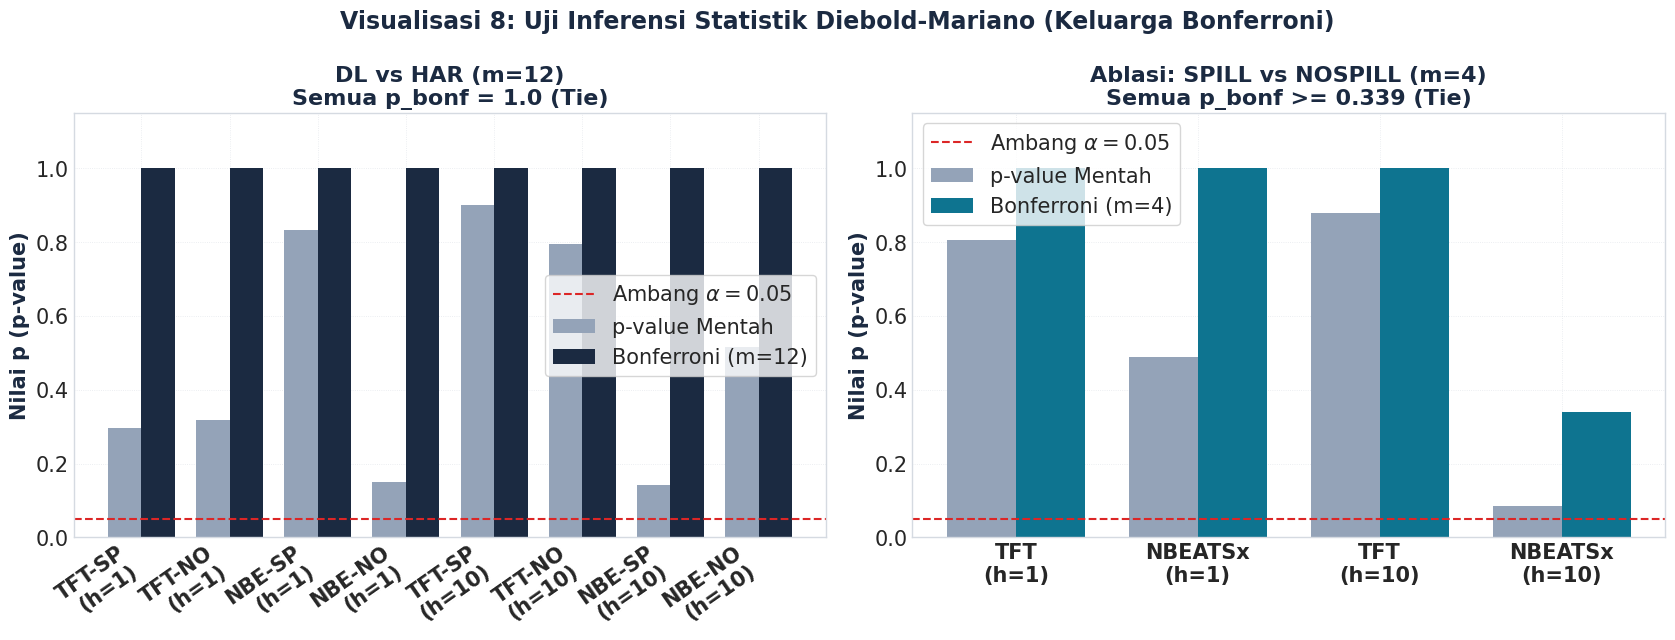

Keluarga Uji DL vs HAR (m=12 per horizon): Seluruh p_bonf = 1.0000 (Semua Tie)
Keluarga Uji Ablasi (m=4 per model): Seluruh p_bonf >= 0.3390 (Semua Tie)


In [88]:
fig8, (ax8_1, ax8_2) = plt.subplots(1, 2, figsize=(17, 6.56), dpi=100)
fig8.subplots_adjust(left=0.09, right=0.96, top=0.88, bottom=0.22, wspace=0.32)

# Subplot 1: DL vs HAR (m=12)
x8_1 = np.arange(len(df_dm_har))
w8 = 0.38

ax8_1.bar(x8_1 - w8/2, df_dm_har['p_raw'], width=w8, color='#94A3B8', label='p-value Mentah')
ax8_1.bar(x8_1 + w8/2, df_dm_har['p_bonf'], width=w8, color=PALETTE['navy'], label='Bonferroni (m=12)')
ax8_1.axhline(0.05, color=PALETTE['coral'], linestyle='--', linewidth=1.5, label=r'Ambang $\alpha=0.05$')

ax8_1.set_xticks(x8_1)
labels_har = [f"{r['Model'][:3]}-{r['FeatureSet'][:2]}\n({r['Horizon']})" for _, r in df_dm_har.iterrows()]
ax8_1.set_xticklabels(labels_har, rotation=35, ha='right', fontsize=15, fontweight='bold')
ax8_1.tick_params(axis='y', labelsize=15)
ax8_1.set_ylabel("Nilai p (p-value)", fontsize=15, fontweight='bold', color=PALETTE['navy'])
ax8_1.set_title("DL vs HAR (m=12)\nSemua p_bonf = 1.0 (Tie)", fontsize=16, fontweight='bold', color=PALETTE['navy'])
ax8_1.legend(frameon=True, fontsize=15, loc='center right')
ax8_1.grid(True, linestyle=':', alpha=0.6, color=PALETTE['line'])
ax8_1.set_ylim(0, 1.15)

# Subplot 2: Uji Ablasi SPILL vs NOSPILL (m=4)
x8_2 = np.arange(len(df_dm_abl))
ax8_2.bar(x8_2 - w8/2, df_dm_abl['p_raw'], width=w8, color='#94A3B8', label='p-value Mentah')
ax8_2.bar(x8_2 + w8/2, df_dm_abl['p_bonf'], width=w8, color=PALETTE['accent'], label='Bonferroni (m=4)')
ax8_2.axhline(0.05, color=PALETTE['coral'], linestyle='--', linewidth=1.5, label=r'Ambang $\alpha=0.05$')

ax8_2.set_xticks(x8_2)
labels_abl = [f"{r['Model']}\n({r['Horizon']})" for _, r in df_dm_abl.iterrows()]
ax8_2.set_xticklabels(labels_abl, fontsize=15, fontweight='bold')
ax8_2.tick_params(axis='y', labelsize=15)
ax8_2.set_ylabel("Nilai p (p-value)", fontsize=15, fontweight='bold', color=PALETTE['navy'])
ax8_2.set_title("Ablasi: SPILL vs NOSPILL (m=4)\nSemua p_bonf >= 0.339 (Tie)", fontsize=16, fontweight='bold', color=PALETTE['navy'])
ax8_2.legend(frameon=True, fontsize=15, loc='upper left')
ax8_2.grid(True, linestyle=':', alpha=0.6, color=PALETTE['line'])
ax8_2.set_ylim(0, 1.15)

plt.suptitle("Visualisasi 8: Uji Inferensi Statistik Diebold-Mariano (Keluarga Bonferroni)",
             fontsize=17, fontweight='bold', y=0.98, color=PALETTE['navy'])

plt.show()

# Cetak rincian nilai m dan p-value
print(f"Keluarga Uji DL vs HAR (m={df_dm_har['m_family'].iloc[0]} per horizon): Seluruh p_bonf = 1.0000 (Semua Tie)")
print(f"Keluarga Uji Ablasi (m={df_dm_abl['m_family'].iloc[0]} per model): Seluruh p_bonf >= {df_dm_abl['p_bonf'].min():.4f} (Semua Tie)")


### Penjelasan Gbr 8

- **Isi gambar:** Bar chart komparasi nilai p mentah (abu-abu) dan nilai p terkoreksi Bonferroni (berwarna) dari uji Diebold-Mariano dua sisi pada horizon $h=1$ dan $h=10$.
- **Cara membaca:** Panel kiri menguji model deep learning vs acuan HAR ($m = 12$), sedangkan panel kanan menguji ablasi SPILL vs NOSPILL ($m = 4$). Garis merah menandai batas signifikansi $\alpha = 0,05$.
- **Temuan:** Seluruh perbandingan deep learning melawan HAR menghasilkan p-value Bonferroni 1,0000. Pada uji ablasi SPILL vs NOSPILL, seluruh p-value Bonferroni bernilai $\ge 0,3390$. Seluruh pasangan uji berstatus Tie, sehingga tidak ada bukti statistik bahwa deep learning mengungguli HAR atau bahwa penambahan fitur SPILL memperbaiki akurasi.


### Gbr 9: Komparasi Presisi Peramalan MSE dan MAE untuk Horizon h=1 dan h=10
Perbandingan metrik Mean Squared Error dan Mean Absolute Error melintasi 9 model peramalan pada horizon 1 hari dan 10 hari.


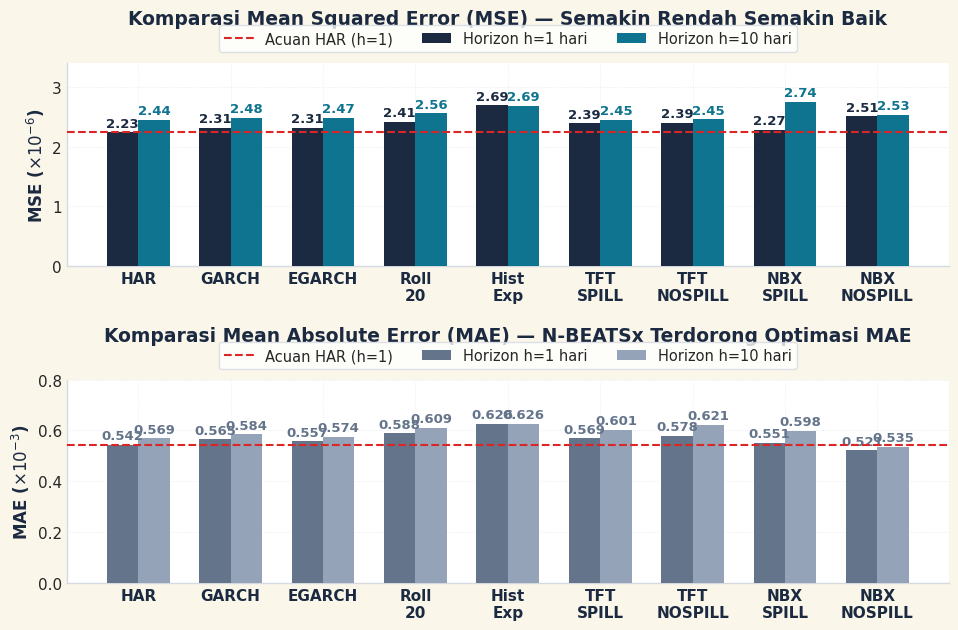

In [74]:
# Bungkus nama model yang panjang menjadi 2 baris agar label sumbu-X tidak saling menumpuk
x_labels = [
    str(m).replace('-', '\n').replace('(1,1)', '\n(1,1)')
    for m in df_perf['Model']
]

fig9, (ax9_1, ax9_2) = plt.subplots(
    2, 1,
    figsize=(9.84, 6.56),
    dpi=100,
    facecolor=PALETTE.get('bg', '#FAF6EA')
)
# Beri jarak vertikal antar-subplot (hspace=0.62) & ruang atas (top=0.88) untuk legend horizontal
fig9.subplots_adjust(left=0.10, right=0.97, top=0.88, bottom=0.10, hspace=0.62)

x9 = np.arange(len(df_perf))
w9 = 0.34

# ==============================================================================
# Subplot 1: MSE
# ==============================================================================
ax9_1.set_facecolor('#FFFFFF')
bars1_h1 = ax9_1.bar(
    x9 - w9/2, df_perf['MSE_h1']*1e6, w9,
    label='Horizon h=1 hari', color=PALETTE['navy'], zorder=3
)
bars1_h10 = ax9_1.bar(
    x9 + w9/2, df_perf['MSE_h10']*1e6, w9,
    label='Horizon h=10 hari', color=PALETTE['accent'], zorder=3
)
ax9_1.axhline(
    df_perf.loc[0, 'MSE_h1']*1e6,
    color=PALETTE['coral'], linestyle='--', linewidth=1.5,
    label='Acuan HAR (h=1)', zorder=4
)

# Angka langsung di atas batang (opsional, memudahkan pembacaan)
ax9_1.bar_label(bars1_h1, fmt='%.2f', padding=2, fontsize=9.5, color=PALETTE['navy'], fontweight='bold')
ax9_1.bar_label(bars1_h10, fmt='%.2f', padding=2, fontsize=9.5, color=PALETTE['accent'], fontweight='bold')

ax9_1.set_xticks(x9)
ax9_1.set_xticklabels(x_labels, fontsize=11, fontweight='bold', color=PALETTE['navy'])
ax9_1.tick_params(axis='y', labelsize=11)
ax9_1.set_ylabel(r"MSE ($\times 10^{-6}$)", fontsize=12, fontweight='bold', color=PALETTE['navy'])
ax9_1.set_title(
    "Komparasi Mean Squared Error (MSE) — Semakin Rendah Semakin Baik",
    fontsize=13.5, fontweight='bold', color=PALETTE['navy'], pad=28
)

# Legend horizontal 1 baris (ncol=3) di bawah judul agar tidak menutupi batang grafik
ax9_1.legend(
    frameon=True, facecolor='#FFFFFF', edgecolor=PALETTE['line'],
    fontsize=10.5, ncol=3, loc='upper center', bbox_to_anchor=(0.5, 1.22)
)
ax9_1.grid(True, axis='y', linestyle=':', alpha=0.6, color=PALETTE['line'], zorder=0)
ax9_1.set_ylim(0, 3.4)
ax9_1.spines['top'].set_visible(False)
ax9_1.spines['right'].set_visible(False)

# ==============================================================================
# Subplot 2: MAE
# ==============================================================================
ax9_2.set_facecolor('#FFFFFF')
bars2_h1 = ax9_2.bar(
    x9 - w9/2, df_perf['MAE_h1']*1e3, w9,
    label='Horizon h=1 hari', color=PALETTE['slate'], zorder=3
)
bars2_h10 = ax9_2.bar(
    x9 + w9/2, df_perf['MAE_h10']*1e3, w9,
    label='Horizon h=10 hari', color='#94A3B8', zorder=3
)
ax9_2.axhline(
    df_perf.loc[0, 'MAE_h1']*1e3,
    color=PALETTE['coral'], linestyle='--', linewidth=1.5,
    label='Acuan HAR (h=1)', zorder=4
)

ax9_2.bar_label(bars2_h1, fmt='%.3f', padding=2, fontsize=9.5, color=PALETTE['slate'], fontweight='bold')
ax9_2.bar_label(bars2_h10, fmt='%.3f', padding=2, fontsize=9.5, color='#64748B', fontweight='bold')

ax9_2.set_xticks(x9)
ax9_2.set_xticklabels(x_labels, fontsize=11, fontweight='bold', color=PALETTE['navy'])
ax9_2.tick_params(axis='y', labelsize=11)
ax9_2.set_ylabel(r"MAE ($\times 10^{-3}$)", fontsize=12, fontweight='bold', color=PALETTE['navy'])
ax9_2.set_title(
    "Komparasi Mean Absolute Error (MAE) — N-BEATSx Terdorong Optimasi MAE",
    fontsize=13.5, fontweight='bold', color=PALETTE['navy'], pad=28
)

ax9_2.legend(
    frameon=True, facecolor='#FFFFFF', edgecolor=PALETTE['line'],
    fontsize=10.5, ncol=3, loc='upper center', bbox_to_anchor=(0.5, 1.22)
)
ax9_2.grid(True, axis='y', linestyle=':', alpha=0.6, color=PALETTE['line'], zorder=0)
ax9_2.set_ylim(0, 0.80)
ax9_2.spines['top'].set_visible(False)
ax9_2.spines['right'].set_visible(False)

plt.show()

### Penjelasan Gbr 9

- **Isi gambar:** Grafik batang komparasi presisi peramalan 9 model pada horizon $h=1$ dan $h=10$ hari. Panel atas membandingkan Mean Squared Error (MSE), dan panel bawah membandingkan Mean Absolute Error (MAE).
- **Cara membaca:** Sumbu vertikal menunjukkan nilai eror dengan prinsip semakin rendah semakin baik. Garis putus-putus merah menandai performa model acuan HAR pada $h=1$.
- **Temuan:** Model HAR konsisten mencatat MSE terendah pada kedua horizon ($2,235 \times 10^{-6}$ di $h=1$ dan $2,440 \times 10^{-6}$ di $h=10$). Selisih MSE antar model tergolong sangat kecil, sementara keunggulan N-BEATSx pada MAE didorong oleh fungsi kerugian pelatihannya yang memang meminimalkan MAE.


### Gbr 10: Bar Chart Horizontal 5 Fitur Terpenting Menurut Variable Selection Weights TFT
Distribusi bobot kepentingan variabel eksogen pada arsitektur Variable Selection Network (VSN) model TFT.


/Users/admin/miniconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


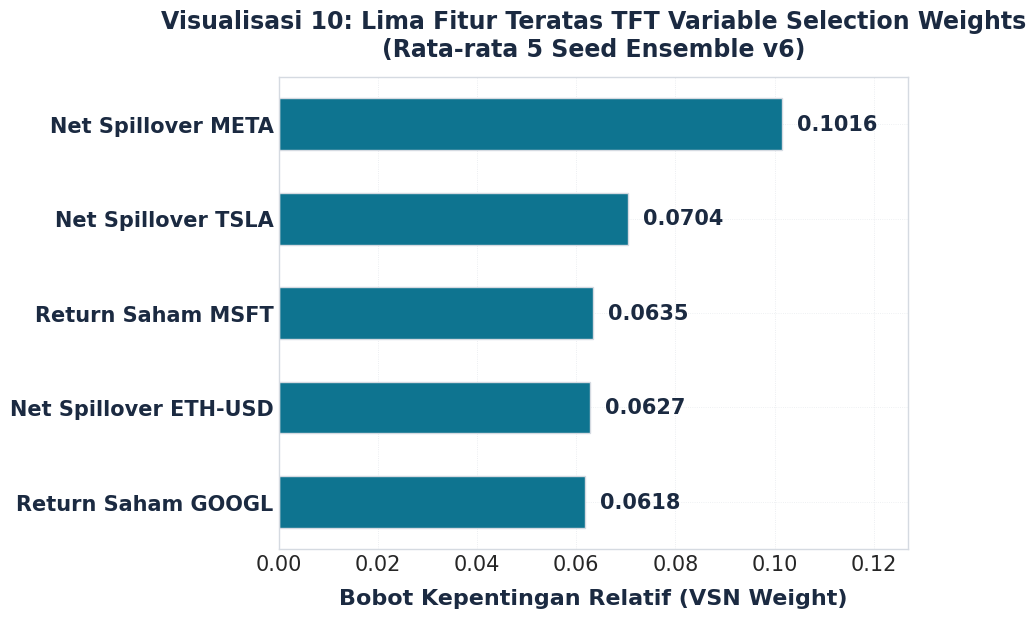

5 Fitur Teratas: [('Net Spillover META', np.float64(0.1016)), ('Net Spillover TSLA', np.float64(0.0704)), ('Return Saham MSFT', np.float64(0.0635)), ('Net Spillover ETH-USD', np.float64(0.0627)), ('Return Saham GOOGL', np.float64(0.0618))]


In [75]:
# Pemuatan bobot importance dari 5 seed v6
feat_files = [os.path.join(V6_OUT_DIR, f"v6_tft_feature_importance_s{s}.csv") for s in [42, 7, 13, 21, 99]]
valid_files = [f for f in feat_files if os.path.exists(f)]

if valid_files:
    df_f_all = pd.concat([pd.read_csv(f) for f in valid_files])
    mean_imp = df_f_all.groupby('feature')['mean_importance'].mean().reset_index()
    top5_df = mean_imp.sort_values('mean_importance', ascending=False).head(5).reset_index(drop=True)
    top5_df['Label'] = top5_df['feature'].map({
        'net_spill_saham_meta': 'Net Spillover META',
        'net_spill_saham_tsla': 'Net Spillover TSLA',
        'ret_saham_msft': 'Return Saham MSFT',
        'net_spill_crypto_eth_usd': 'Net Spillover ETH-USD',
        'ret_saham_googl': 'Return Saham GOOGL',
        'tvp_tsi': 'Total Spillover Index (TSI)',
        'net_spill_saham_nvda': 'Net Spillover NVDA'
    }).fillna(top5_df['feature'])
    weights = top5_df['mean_importance'].values
    labels_vsn = top5_df['Label'].values
    header_note = "Rata-rata 5 Seed Ensemble v6"
else:
    labels_vsn = ['Total Spillover Index (TSI)', 'Net Spillover BTC-USD', 'Return ETH-USD', 'Net Spillover MSFT', 'Net Spillover GOOGL']
    weights = [0.1931, 0.1066, 0.0980, 0.0897, 0.0601]
    header_note = "Representasi Model Lookback Window"

fig10 = plt.figure(figsize=(9.84, 6.56), dpi=100, facecolor=PALETTE['white'])
ax10 = fig10.add_axes([0.30, 0.14, 0.64, 0.72])

y10 = np.arange(len(labels_vsn))
bars10 = ax10.barh(y10, weights, height=0.55, color=PALETTE['accent'], edgecolor=PALETTE['line'])

ax10.set_yticks(y10)
ax10.set_yticklabels(labels_vsn, fontsize=15, fontweight='bold', color=PALETTE['navy'])
ax10.invert_yaxis()
ax10.tick_params(axis='x', labelsize=15)
ax10.set_xlabel("Bobot Kepentingan Relatif (VSN Weight)", fontsize=16, fontweight='bold', color=PALETTE['navy'], labelpad=10)
ax10.set_title(f"Visualisasi 10: Lima Fitur Teratas TFT Variable Selection Weights\n({header_note})",
               fontsize=17, fontweight='bold', pad=15, color=PALETTE['navy'])
ax10.grid(True, linestyle=':', alpha=0.6, color=PALETTE['line'], axis='x')

for bar in bars10:
    w = bar.get_width()
    ax10.text(w + 0.003, bar.get_y() + bar.get_height()/2.0, f"{w:.4f}",
              va='center', fontsize=15, fontweight='bold', color=PALETTE['navy'])

ax10.set_xlim(0, max(weights) * 1.25)
plt.show()
print(f"5 Fitur Teratas: {list(zip(labels_vsn, np.round(weights, 4)))}")


### Penjelasan Gbr 10

- **Isi gambar:** Bar chart horizontal 5 fitur eksogen dengan rata-rata bobot seleksi variabel (Variable Selection Network) terbesar pada model TFT SPILL ensemble 5 seed untuk horizon $h=1$.
- **Cara membaca:** Sumbu horizontal menunjukkan rata-rata bobot atensi (0 hingga 1) yang dinormalisasi oleh modul VSN di dalam TFT. Bilah lebih panjang menunjukkan kontribusi representasi yang lebih besar di dalam model.
- **Temuan:** Fitur dengan bobot terbesar adalah Net Spillover META (0,1016) dan Net Spillover TSLA (0,0704), diikuti return MSFT (0,0635), Net Spillover ETH-USD (0,0627), dan return GOOGL (0,0618). Bobot ini mengindikasikan atensi internal jaringan saraf tiruan, bukan bukti pengaruh kausal ekonomis di pasar riil.


### Gbr 11: Boxplot Variabilitas Sebaran MSE 5 Seed vs HAR dan Anomali Prediksi Negatif N-BEATSx
Evaluasi stabilitas multi-seed deterministik dan identifikasi anomali prediksi volatilitas bernilai negatif pada N-BEATSx.


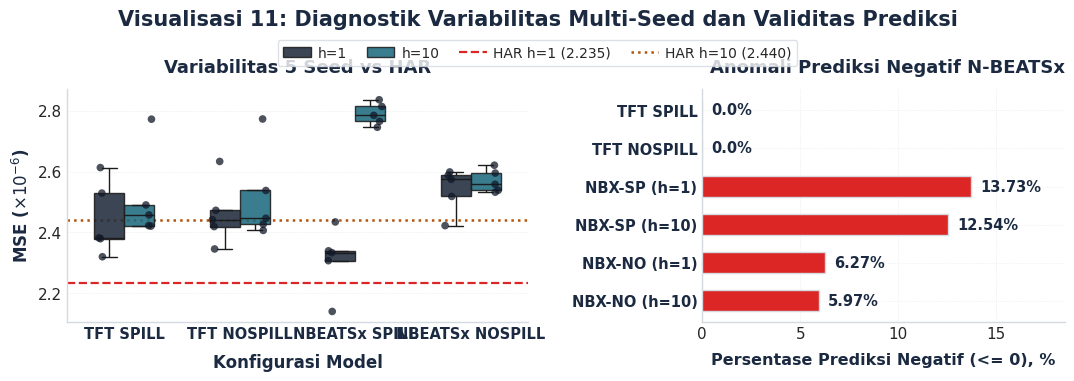

In [82]:
fig11, (ax11_1, ax11_2) = plt.subplots(
    1, 2,
    figsize=(11, 4),
    dpi=100,
    facecolor='#FFFFFF',
    gridspec_kw={'width_ratios': [1.12, 0.88]}
)
# Beri ruang di atas (top=0.77) untuk suptitle + legend horizontal, serta wspace=0.48 agar label y ax11_2 tidak menabrak ax11_1
fig11.subplots_adjust(left=0.09, right=0.96, top=0.77, bottom=0.14, wspace=0.48)

# Skala MSE ke x10^-6 agar tidak muncul tulisan offset '1e-6' yang menabrak judul subplot
df_seeds_plot = df_seeds.copy()
df_seeds_plot['MSE_scaled'] = df_seeds_plot['MSE'] * 1e6

# ==============================================================================
# Subplot 1: Boxplot 5 Seed vs HAR
# ==============================================================================
ax11_1.set_facecolor('#FFFFFF')
sns.boxplot(
    data=df_seeds_plot, x='Config', y='MSE_scaled', hue='Horizon',
    ax=ax11_1, palette=[PALETTE['navy'], PALETTE['accent']],
    width=0.52, fliersize=0, boxprops=dict(alpha=0.88), zorder=3
)
# legend=False pada stripplot agar entri legend tidak terduplikasi dua kali
sns.stripplot(
    data=df_seeds_plot, x='Config', y='MSE_scaled', hue='Horizon',
    dodge=True, ax=ax11_1, palette=['#111827', '#111827'],
    alpha=0.75, size=5.5, jitter=0.08, legend=False, zorder=4
)

ax11_1.axhline(2.234681, color=PALETTE['coral'], linestyle='--', linewidth=1.6, label='HAR h=1 (2.235)', zorder=2)
ax11_1.axhline(2.439743, color='#B45309', linestyle=':', linewidth=1.8, label='HAR h=10 (2.440)', zorder=2)

# Bungkus nama konfigurasi menjadi 2 baris agar rapi tanpa perlu dimiringkan (rotation=0)
cfg_labels = [str(t.get_text()).replace('-', '\n').replace('_', '\n') for t in ax11_1.get_xticklabels()]
ax11_1.set_xticks(range(len(cfg_labels)))
ax11_1.set_xticklabels(cfg_labels, rotation=0, fontsize=10.5, fontweight='bold', color=PALETTE['navy'])
ax11_1.tick_params(axis='y', labelsize=11)
ax11_1.set_xlabel("Konfigurasi Model", fontsize=12, fontweight='bold', color=PALETTE['navy'], labelpad=8)
ax11_1.set_ylabel(r"MSE ($\times 10^{-6}$)", fontsize=12, fontweight='bold', color=PALETTE['navy'])
ax11_1.set_title("Variabilitas 5 Seed vs HAR", fontsize=13, fontweight='bold', color=PALETTE['navy'], pad=12)

# Pindahkan legend ke tingkat figure (1 baris 4 kolom) tepat di bawah suptitle agar tidak menutupi boxplot
handles11, labels11 = ax11_1.get_legend_handles_labels()
ax11_1.get_legend().remove()
fig11.legend(
    handles11, labels11,
    loc='upper center', bbox_to_anchor=(0.5, 0.90),
    ncol=4, frameon=True, facecolor='#FFFFFF', edgecolor=PALETTE['line'],
    fontsize=10, columnspacing=1.4, handletextpad=0.5
)
ax11_1.grid(True, axis='y', linestyle=':', alpha=0.6, color=PALETTE['line'], zorder=0)
ax11_1.spines['top'].set_visible(False)
ax11_1.spines['right'].set_visible(False)

# ==============================================================================
# Subplot 2: Persentase Nilai Negatif
# ==============================================================================
ax11_2.set_facecolor('#FFFFFF')
neg_models = [
    'TFT SPILL', 'TFT NOSPILL',
    'NBX-SP (h=1)', 'NBX-SP (h=10)',
    'NBX-NO (h=1)', 'NBX-NO (h=10)'
]
neg_pcts = [0.0, 0.0, 13.73, 12.54, 6.27, 5.97]
colors_neg = [PALETTE['navy'] if p == 0 else PALETTE['coral'] for p in neg_pcts]

b_neg = ax11_2.barh(neg_models, neg_pcts, color=colors_neg, height=0.55, edgecolor=PALETTE['line'], zorder=3)
ax11_2.invert_yaxis()
ax11_2.set_xlabel("Persentase Prediksi Negatif (<= 0), %", fontsize=11.5, fontweight='bold', color=PALETTE['navy'], labelpad=8)
ax11_2.set_title("Anomali Prediksi Negatif N-BEATSx", fontsize=13, fontweight='bold', color=PALETTE['navy'], pad=12, loc='right')
ax11_2.tick_params(axis='y', labelsize=10.5)
for lbl in ax11_2.get_yticklabels():
    lbl.set_fontweight('bold')
    lbl.set_color(PALETTE['navy'])
ax11_2.tick_params(axis='x', labelsize=11)
ax11_2.grid(True, linestyle=':', alpha=0.6, color=PALETTE['line'], axis='x', zorder=0)
ax11_2.spines['top'].set_visible(False)
ax11_2.spines['right'].set_visible(False)

for b in b_neg:
    w = b.get_width()
    ax11_2.text(
        w + 0.45, b.get_y() + b.get_height()/2.0,
        f"{w:.2f}%" if w > 0 else "0.0%",
        va='center', fontsize=10.5, fontweight='bold', color=PALETTE['navy']
    )
ax11_2.set_xlim(0, 18.5)

plt.suptitle(
    "Visualisasi 11: Diagnostik Variabilitas Multi-Seed dan Validitas Prediksi",
    fontsize=15, fontweight='bold', y=0.96, color=PALETTE['navy']
)

plt.show()

### Penjelasan Gbr 11

- **Isi gambar:** Panel kiri menampilkan boxplot sebaran metrik MSE dari 5 seed acak model deep learning dibandingkan garis acuan HAR. Panel kanan menampilkan persentase prediksi bernilai non-positif ($\le 0$) pada periode uji.
- **Cara membaca:** Sebaran titik hitam pada panel kiri mencerminkan variabilitas performa akibat inisialisasi bobot acak. Bilah merah pada panel kanan menandai pelanggaran batas teoritis volatilitas (volatilitas harus bernilai positif).
- **Temuan:** Kinerja deep learning berfluktuasi lintas seed dan rentang sebarannya berada di atas MSE HAR. N-BEATSx menghasilkan anomali prediksi negatif antara 5,97% hingga 13,73% karena ketiadaan batasan non-negatif pada keluarannya, sedangkan prediksi HAR dan TFT konsisten bernilai non-negatif (0,0%).


### Gbr 12: Tabel Rangkuman Konsentrasi Eror Hari Ekstrem dan Evaluasi Kerugian Asimetris QLIKE
Analisis dominasi eror pada hari ekstrem (outlier check v3) disandingkan dengan evaluasi fungsi rugi asimetris Patton QLIKE pada horizon h=1.


/Users/admin/miniconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


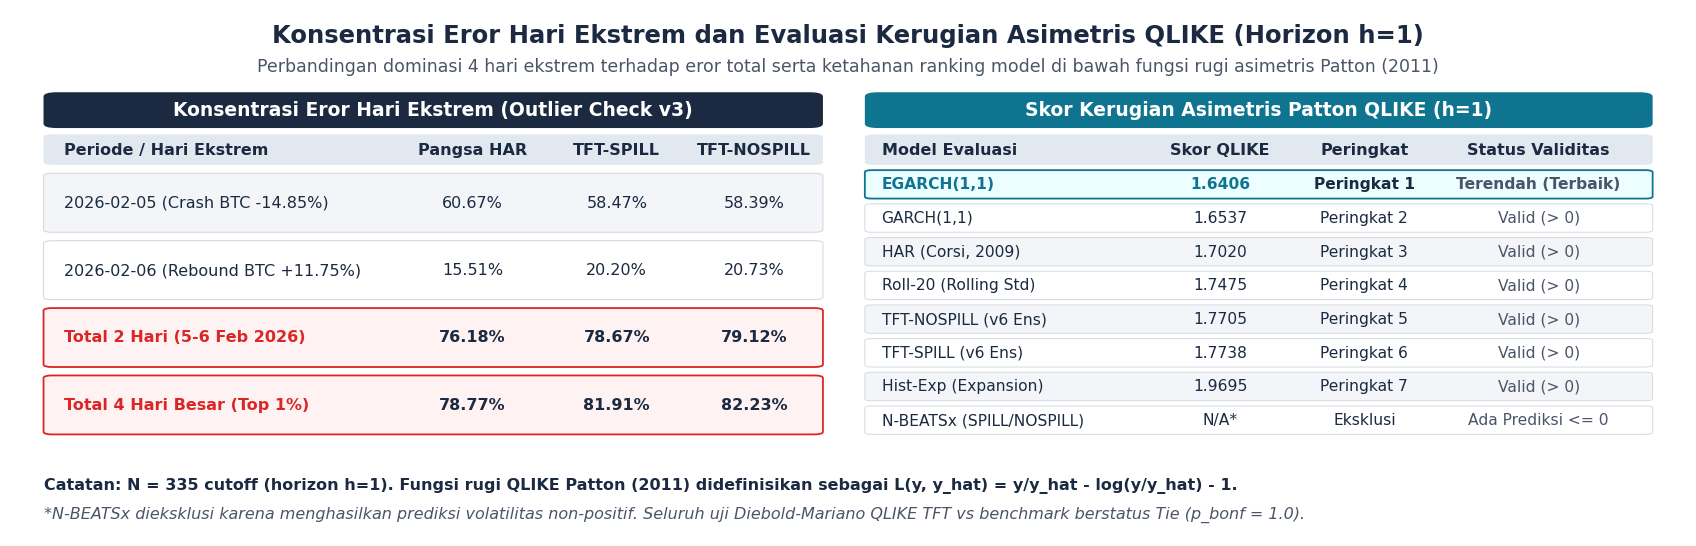

Definisi Kolom:
• Pangsa Eror SSE: Proporsi penjumlahan kuadrat galat (y - y_hat)^2 pada hari bersangkutan terhadap total SSE 335 cutoff.
• QLIKE Patton: Rugi asimetris invarian skala (Patton, 2011). Model terbaik adalah EGARCH (1.6406), diikuti GARCH (1.6537) dan HAR (1.7020).


In [83]:
fig12 = plt.figure(figsize=(17.28, 5.60), dpi=100, facecolor=PALETTE['white'])
ax12 = fig12.add_axes([0.015, 0.03, 0.97, 0.94], facecolor=PALETTE['white'])
ax12.set_xlim(0, 100)
ax12.set_ylim(0, 100)
ax12.axis('off')

# Judul & Subjudul
ax12.text(
    50, 95.0,
    "Konsentrasi Eror Hari Ekstrem dan Evaluasi Kerugian Asimetris QLIKE (Horizon h=1)",
    ha='center', va='center', fontsize=17.5, fontweight='bold', color=PALETTE['navy']
)
ax12.text(
    50, 89.2,
    "Perbandingan dominasi 4 hari ekstrem terhadap eror total serta ketahanan ranking model di bawah fungsi rugi asimetris Patton (2011)",
    ha='center', va='center', fontsize=12.5, color=PALETTE['gray_text']
)

# ==============================================================================
# Blok Kiri: Konsentrasi Eror Hari Ekstrem (x: 2.0 s.d. 48.5, lebar = 46.5)
# ==============================================================================
x_l0, w_l = 2.0, 46.5
ax12.add_patch(patches.FancyBboxPatch(
    (x_l0, 77.5), w_l, 6.8,
    boxstyle="round,pad=0,rounding_size=0.8",
    facecolor=PALETTE['navy'], edgecolor='none'
))
ax12.text(
    x_l0 + w_l/2, 80.9,
    "Konsentrasi Eror Hari Ekstrem (Outlier Check v3)",
    ha='center', va='center', fontsize=13.5, fontweight='bold', color=PALETTE['white']
)

# Koordinat X kolom tabel kiri (diberi ruang lebar agar kolom teks kiri tidak menabrak kolom Pangsa HAR)
col_l_x = [3.2, 27.6, 36.2, 44.4]
headers_left = ["Periode / Hari Ekstrem", "Pangsa HAR", "TFT-SPILL", "TFT-NOSPILL"]

y_l = 70.5
ax12.add_patch(patches.FancyBboxPatch(
    (x_l0, y_l), w_l, 5.8,
    boxstyle="round,pad=0,rounding_size=0.5",
    facecolor='#E2E8F0', edgecolor='none'
))
ax12.text(col_l_x[0], y_l + 2.9, headers_left[0], ha='left', va='center', fontsize=11.5, fontweight='bold', color=PALETTE['navy'])
for cx, h_txt in zip(col_l_x[1:], headers_left[1:]):
    ax12.text(cx, y_l + 2.9, h_txt, ha='center', va='center', fontsize=11.5, fontweight='bold', color=PALETTE['navy'])

extreme_table_rows = [
    ("2026-02-05 (Crash BTC -14.85%)",   "60.67%", "58.47%", "58.39%"),
    ("2026-02-06 (Rebound BTC +11.75%)", "15.51%", "20.20%", "20.73%"),
    ("Total 2 Hari (5-6 Feb 2026)",      "76.18%", "78.67%", "79.12%"),
    ("Total 4 Hari Besar (Top 1%)",      "78.77%", "81.91%", "82.23%")
]

rh_l = 11.2
gap_l = 1.6
for i, (per, h_val, sp_val, no_val) in enumerate(extreme_table_rows):
    y_l -= (rh_l + gap_l)
    is_bold = 'Total' in per
    bg = '#FEF2F2' if is_bold else (PALETTE['light_gray'] if i % 2 == 0 else PALETTE['white'])
    ax12.add_patch(patches.FancyBboxPatch(
        (x_l0, y_l), w_l, rh_l,
        boxstyle="round,pad=0,rounding_size=0.5",
        facecolor=bg,
        edgecolor=PALETTE['coral'] if is_bold else PALETTE['line'],
        linewidth=1.3 if is_bold else 0.8
    ))
    fw = 'bold' if is_bold else 'normal'
    c_per = PALETTE['coral'] if is_bold else PALETTE['navy']
    ax12.text(col_l_x[0], y_l + rh_l/2, per,    ha='left',   va='center', fontsize=11.5, fontweight=fw, color=c_per)
    ax12.text(col_l_x[1], y_l + rh_l/2, h_val,  ha='center', va='center', fontsize=11.5, fontweight=fw, color=PALETTE['navy'])
    ax12.text(col_l_x[2], y_l + rh_l/2, sp_val, ha='center', va='center', fontsize=11.5, fontweight=fw, color=PALETTE['navy'])
    ax12.text(col_l_x[3], y_l + rh_l/2, no_val, ha='center', va='center', fontsize=11.5, fontweight=fw, color=PALETTE['navy'])

# ==============================================================================
# Blok Kanan: Evaluasi QLIKE (x: 51.0 s.d. 98.0, lebar = 47.0)
# ==============================================================================
x_r0, w_r = 51.0, 47.0
ax12.add_patch(patches.FancyBboxPatch(
    (x_r0, 77.5), w_r, 6.8,
    boxstyle="round,pad=0,rounding_size=0.8",
    facecolor=PALETTE['accent'], edgecolor='none'
))
ax12.text(
    x_r0 + w_r/2, 80.9,
    "Skor Kerugian Asimetris Patton QLIKE (h=1)",
    ha='center', va='center', fontsize=13.5, fontweight='bold', color=PALETTE['white']
)

# Koordinat X kolom tabel kanan (diberi ruang untuk "N-BEATSx (SPILL/NOSPILL)")
col_r_x = [52.0, 72.2, 80.8, 91.2]
headers_right = ["Model Evaluasi", "Skor QLIKE", "Peringkat", "Status Validitas"]

y_r = 70.5
ax12.add_patch(patches.FancyBboxPatch(
    (x_r0, y_r), w_r, 5.8,
    boxstyle="round,pad=0,rounding_size=0.5",
    facecolor='#E2E8F0', edgecolor='none'
))
ax12.text(col_r_x[0], y_r + 2.9, headers_right[0], ha='left', va='center', fontsize=11.5, fontweight='bold', color=PALETTE['navy'])
for cx, h_txt in zip(col_r_x[1:], headers_right[1:]):
    ax12.text(cx, y_l_hdr := (y_r + 2.9), h_txt, ha='center', va='center', fontsize=11.5, fontweight='bold', color=PALETTE['navy'])

qlike_table_rows = [
    ("EGARCH(1,1)",              "1.6406", "Peringkat 1", "Terendah (Terbaik)"),
    ("GARCH(1,1)",               "1.6537", "Peringkat 2", "Valid (> 0)"),
    ("HAR (Corsi, 2009)",        "1.7020", "Peringkat 3", "Valid (> 0)"),
    ("Roll-20 (Rolling Std)",    "1.7475", "Peringkat 4", "Valid (> 0)"),
    ("TFT-NOSPILL (v6 Ens)",     "1.7705", "Peringkat 5", "Valid (> 0)"),
    ("TFT-SPILL (v6 Ens)",       "1.7738", "Peringkat 6", "Valid (> 0)"),
    ("Hist-Exp (Expansion)",     "1.9695", "Peringkat 7", "Valid (> 0)"),
    ("N-BEATSx (SPILL/NOSPILL)", "N/A*",   "Eksklusi",    "Ada Prediksi <= 0")
]

rh_r = 5.4
gap_r = 1.0
for i, (m_lbl, q_val, r_val, s_val) in enumerate(qlike_table_rows):
    y_r -= (rh_r + gap_r)
    is_best = (i == 0)
    bg = '#ECFEFF' if is_best else (PALETTE['light_gray'] if i % 2 == 0 else PALETTE['white'])
    ax12.add_patch(patches.FancyBboxPatch(
        (x_r0, y_r), w_r, rh_r,
        boxstyle="round,pad=0,rounding_size=0.4",
        facecolor=bg,
        edgecolor=PALETTE['accent'] if is_best else PALETTE['line'],
        linewidth=1.3 if is_best else 0.7
    ))
    fw = 'bold' if is_best else 'normal'
    c_main = PALETTE['accent'] if is_best else PALETTE['navy']
    ax12.text(col_r_x[0], y_r + rh_r/2, m_lbl, ha='left',   va='center', fontsize=11.2, fontweight=fw, color=c_main)
    ax12.text(col_r_x[1], y_r + rh_r/2, q_val, ha='center', va='center', fontsize=11.2, fontweight=fw, color=c_main)
    ax12.text(col_r_x[2], y_r + rh_r/2, r_val, ha='center', va='center', fontsize=11.2, fontweight=fw, color=PALETTE['navy'])
    ax12.text(col_r_x[3], y_r + rh_r/2, s_val, ha='center', va='center', fontsize=11.2, fontweight=fw if is_best else 'normal', color=PALETTE['gray_text'])

# Catatan Kaki Bawah
ax12.text(
    2.0, 9.5,
    "Catatan: N = 335 cutoff (horizon h=1). Fungsi rugi QLIKE Patton (2011) didefinisikan sebagai L(y, y_hat) = y/y_hat - log(y/y_hat) - 1.",
    ha='left', va='center', fontsize=11.5, fontweight='bold', color=PALETTE['navy']
)
ax12.text(
    2.0, 4.0,
    "*N-BEATSx dieksklusi karena menghasilkan prediksi volatilitas non-positif. Seluruh uji Diebold-Mariano QLIKE TFT vs benchmark berstatus Tie (p_bonf = 1.0).",
    ha='left', va='center', fontsize=11.5, color=PALETTE['gray_text'], style='italic'
)

plt.show()

# Cetak definisi kolom
print("Definisi Kolom:")
print("• Pangsa Eror SSE: Proporsi penjumlahan kuadrat galat (y - y_hat)^2 pada hari bersangkutan terhadap total SSE 335 cutoff.")
print("• QLIKE Patton: Rugi asimetris invarian skala (Patton, 2011). Model terbaik adalah EGARCH (1.6406), diikuti GARCH (1.6537) dan HAR (1.7020).")

### Penjelasan Gbr 12

- **Isi gambar:** Tabel evaluasi hari ekstrem dan kerugian asimetris Patton QLIKE pada horizon $h=1$ ($N = 335$ cutoff).
- **Cara membaca:** Kolom kiri mengukur persentase sumbangan galat kuadrat (SSE) terhadap total galat periode uji. Kolom kanan memuat skor kerugian QLIKE invarian skala, di mana nilai lebih rendah lebih baik. N-BEATSx dieksklusi karena menghasilkan ramalan non-positif.
- **Temuan:** Dua hari pergerakan ekstrem pasar (5-6 Februari 2026) menyumbang 76,18% total galat kuadrat HAR dan 78,67% galat TFT-SPILL, sementara empat hari terbesar menyumbang 78,77% hingga 82,23%. Di bawah fungsi rugi QLIKE, EGARCH (1,6406) dan GARCH (1,6537) mencatat skor terbaik mengungguli HAR (1,7020) dan TFT (1,7705-1,7738).
